# Stage 1: embedding comparison with a fixed linear probe

This notebook inlines all experiment modules and does not import the stage1 package. The default mode reads existing caches, verifies inputs and results, and regenerates tables and figures. No weights are downloaded or models fitted in cache-only mode. Run from the repository or notebooks directory with the recorded environment.

In [1]:
RECOMPUTE = False
import os
assert os.environ.get('PYTHONHASHSEED') == '0', 'Start the kernel with PYTHONHASHSEED=0'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
os.environ['MPLBACKEND'] = 'Agg'
os.environ['PYTHONDONTWRITEBYTECODE'] = '1'

## Immutable training inputs and grouped resampling

Only allowlisted files are read. Phrase bytes and group boundaries are checked. Configuration and inlined-source fingerprints are embedded, so runtime does not require stage1 Python files.

In [2]:
"""Allowlisted input access, immutable Phrase fingerprints, and grouped folds."""
import hashlib
import json
import os
import platform
import random
import subprocess
import sys
from pathlib import Path
sys.dont_write_bytecode = True
import numpy as np
import pandas as pd
import yaml
from sklearn.model_selection import StratifiedGroupKFold

def project_root():
    if '__file__' in globals():
        return Path(__file__).resolve().parents[1]
    here = Path.cwd().resolve()
    return here if (here / 'STAGE1_TASK.md').exists() else here.parent
ROOT = project_root()
CONFIG = {'data_dir': 'data/DSAI4205_unified_cleaning_seed42_v3_stemming', 'seed': 42, 'configs': ['w2v', 'ft', 'glove_stem', 'glove_direct', 'bertweet', 'bertweet_pca100', 'baseline_ref'], 'C_grid': [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10], 'repeats': [0, 1, 2, 3, 4], 'outer_splits': 5, 'inner_splits': 3, 'tie_tolerance': 0.001, 'word_vectors': {'vector_size': 100, 'window': 5, 'min_count': 1, 'sg': 1, 'negative': 5, 'epochs': 50, 'workers': 1, 'seed': 42}, 'fasttext': {'min_n': 3, 'max_n': 6}, 'glove': 'glove-twitter-100', 'bertweet': {'checkpoint': 'vinai/bertweet-base', 'max_length': 128, 'batch_size': 8, 'normalization': False, 'pca_components': 100}}
random.seed(CONFIG['seed'])
np.random.seed(CONFIG['seed'])
DATA = ROOT / CONFIG['data_dir']
FEATURES = ROOT / 'features/stage1'
RESULTS = ROOT / 'results/stage1'
FIGURES = ROOT / 'figures/stage1'
REPORTS = ROOT / 'reports/stage1'
LABELS = [0, 1, 2, 3]
CLASS_NAMES = ['Negative', 'Positive', 'Irrelevant', 'Neutral']

def prepare_dirs():
    for path in (FEATURES, RESULTS, FIGURES, REPORTS):
        path.mkdir(parents=True, exist_ok=True)

def file_sha(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

def write_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, ensure_ascii=False) + '\n', encoding='utf-8')

def read_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))

def phrase_sha(phrases):
    digest = hashlib.sha256()
    for phrase in phrases:
        value = phrase.encode('utf-8')
        digest.update(len(value).to_bytes(8, 'big'))
        digest.update(value)
    return digest.hexdigest()

def load_data(stage='read', require_check=True):
    prepare_dirs()
    frame = pd.read_csv(DATA / 'train.csv', encoding='utf-8-sig', keep_default_na=False)
    folds = pd.read_csv(DATA / 'fold_assignments.csv', encoding='utf-8-sig', keep_default_na=False)
    assert list(frame.columns) == ['Phrase', 'Sentiment']
    assert len(frame) == len(folds) == 563
    assert np.array_equal(folds.row_index.to_numpy(), np.arange(563))
    assert folds.sample_id.is_unique and folds.group_id.ne('').all()
    assert np.array_equal(frame.Sentiment.to_numpy(), folds.Sentiment.to_numpy())
    assert set(frame.Sentiment) == set(LABELS)
    assert set(folds.validation_fold) == set(range(1, 6))
    assert all((isinstance(p, str) and p and ('' not in p.split(' ')) for p in frame.Phrase))
    assert int((folds.groupby('group_id').size() > 1).sum()) == 13
    assert folds.groupby('group_id').validation_fold.nunique().max() == 1
    value = phrase_sha(frame.Phrase)
    check_path = RESULTS / 'check.json'
    if require_check:
        if not check_path.exists():
            raise RuntimeError('Run check before using the data')
        check = read_json(check_path)
        assert value == check['phrase_sha256'], 'Phrase changed since check'
        for name in ('train.csv', 'fold_assignments.csv', 'code/unified_data.py'):
            assert file_sha(DATA / name) == check['verified_hashes'][name]
    write_json(RESULTS / f'phrase_{stage}.json', {'stage': stage, 'phrase_sha256': value, 'n_rows': len(frame)})
    return (frame, folds)

def make_repeats(frame, assignments):
    records = []
    for repeat in CONFIG['repeats']:
        allocated = np.zeros(len(frame), dtype=int)
        if repeat == 0:
            allocated[:] = assignments.validation_fold
        else:
            splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=repeat)
            for fold, (_, valid) in enumerate(splitter.split(frame.Phrase, frame.Sentiment, assignments.group_id), 1):
                allocated[valid] = fold
        assert set(allocated) == set(range(1, 6))
        assert pd.DataFrame({'group': assignments.group_id, 'fold': allocated}).groupby('group').fold.nunique().max() == 1
        records.extend(({'row_index': i, 'repeat': repeat, 'fold': int(f)} for i, f in enumerate(allocated)))
    return pd.DataFrame(records)

def check_inputs():
    frame, assignments = load_data('check', require_check=False)
    manifest = read_json(DATA / 'SHA256SUMS.json')
    allowed = ['train.csv', 'fold_assignments.csv', 'code/unified_data.py', 'dataset_config.json', 'README.md']
    verified = {}
    for name in allowed:
        actual = file_sha(DATA / name)
        assert actual == manifest[name], f'Hash mismatch: {name}'
        verified[name] = actual
    repeats = make_repeats(frame, assignments)
    repeats.to_csv(RESULTS / 'folds_repeats.csv', index=False, encoding='utf-8')
    check = {'phrase_sha256': phrase_sha(frame.Phrase), 'n_rows': len(frame), 'verified_hashes': verified, 'unverified_manifest_entries': sorted(set(manifest) - set(allowed)), 'scope': 'Allowlisted extracted files only; forbidden and archived files never opened', 'groups': int(assignments.group_id.nunique()), 'multirow_groups': 13, 'folds_sha256': file_sha(RESULTS / 'folds_repeats.csv')}
    write_json(RESULTS / 'check.json', check)
    print(f'CHECK passed in allowed scope: {len(frame)} rows, 25 grouped folds, {len(verified)} hashes', flush=True)
    return check

def load_repeats(frame, assignments):
    path = RESULTS / 'folds_repeats.csv'
    assert file_sha(path) == read_json(RESULTS / 'check.json')['folds_sha256']
    repeats = pd.read_csv(path, encoding='utf-8')
    pd.testing.assert_frame_equal(repeats, make_repeats(frame, assignments))
    return repeats

def record_environment(command):
    prepare_dirs()
    import importlib.metadata
    packages = ['numpy', 'scipy', 'scikit-learn', 'gensim', 'torch', 'transformers', 'nltk']
    versions = {p: importlib.metadata.version(p) for p in packages}
    info = {'command': command, 'machine': platform.node(), 'platform': platform.platform(), 'python': sys.version, 'versions': versions, 'environment': {key: os.environ.get(key) for key in ['PYTHONHASHSEED', 'PYTHONUTF8', 'OMP_NUM_THREADS', 'MKL_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'TOKENIZERS_PARALLELISM']}}
    freeze = subprocess.check_output([sys.executable, '-m', 'pip', 'freeze'], text=True, encoding='utf-8')
    (RESULTS / f'env_{platform.node()}.txt').write_text(json.dumps(info, indent=2) + '\n\n' + freeze, encoding='utf-8')
    write_json(RESULTS / f'environment_{command}.json', info)

def cache_identity():
    return {'phrase_sha256': read_json(RESULTS / 'check.json')['phrase_sha256'], 'config_sha256': '9702a2822997b6dee21c060b1df98951abf50f61b8bb4037745780dba781ed08', 'embeddings_sha256': '19e970df3cad74b80589b0e32281717ac970b28ae6dec1bf844f7382fd097aad', 'normalizer_sha256': file_sha(DATA / 'code/unified_data.py')}

## Sparse reference representation

The two independently normalized branches are fitted within each training partition.

In [3]:
"""The sole location of the sparse TF-IDF reference representation."""
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import FeatureUnion

def space_tokens(text):
    return text.split(' ')

def baseline_features():
    return FeatureUnion([('word', TfidfVectorizer(analyzer='word', tokenizer=space_tokens, token_pattern=None, lowercase=False, ngram_range=(1, 1), sublinear_tf=True, min_df=2, norm='l2')), ('char', TfidfVectorizer(analyzer='char_wb', lowercase=False, ngram_range=(3, 5), sublinear_tf=True, min_df=2, norm='l2'))])

## Four mean-pooled embeddings

Fold-local word vectors and frozen pretrained features have separate provenance caches.

In [4]:
"""Mean-pooled representations; no labels used for representation fitting."""
import gc
import importlib.util
import os
import pickle
from collections import Counter
import numpy as np
import pandas as pd

def mean_vectors(tokens, lookup, dimension):
    vectors = [lookup(token) for token in tokens]
    vectors = [vector for vector in vectors if vector is not None]
    return np.mean(vectors, axis=0).astype(np.float32) if vectors else np.zeros(dimension, np.float32)

def lexical_coverage(phrases, vocabulary, vectors, embedding, repeat=-1, fold=-1, **extra):
    tokens = [token for phrase in phrases for token in phrase.split(' ')]
    unique = set(tokens)
    missing = [token for token in tokens if token not in vocabulary]
    return {'embedding': embedding, 'repeat': repeat, 'fold': fold, 'token_count': len(tokens), 'type_count': len(unique), 'unseen_token_rate': len(missing) / len(tokens), 'unseen_type_rate': len(set(missing)) / len(unique), 'oov_token_rate': len(missing) / len(tokens), 'oov_type_rate': len(set(missing)) / len(unique), 'zero_rows': int(np.all(vectors == 0, axis=1).sum()), **extra}

def train_word_vectors(kind, phrases, train_indices, valid_indices):
    assert os.environ.get('PYTHONHASHSEED') == '0', 'Set PYTHONHASHSEED=0 before process startup'
    from gensim.models import FastText, Word2Vec
    train_indices = np.asarray(train_indices)
    valid_indices = np.asarray(valid_indices)
    assert len(np.intersect1d(train_indices, valid_indices)) == 0
    assert len(set(train_indices.tolist())) == len(train_indices)
    sentences = [phrases[int(i)].split(' ') for i in train_indices]
    assert len(sentences) == len(train_indices)
    kwargs = dict(CONFIG['word_vectors'])
    cls = Word2Vec if kind == 'w2v' else FastText
    if kind == 'ft':
        kwargs.update(CONFIG['fasttext'])
    model = cls(sentences=sentences, **kwargs)
    vocabulary = set(model.wv.key_to_index)

    def lookup(token):
        return model.wv[token] if kind == 'ft' or token in vocabulary else None
    vectors = np.stack([mean_vectors(p.split(' '), lookup, 100) for p in phrases])
    assert vectors.shape == (len(phrases), 100) and np.isfinite(vectors).all()
    return (vectors, vocabulary)

def fold_word_features(kind, frame, train, valid, repeat, fold, recompute=False):
    path = FEATURES / f'{kind}_r{repeat}_f{fold}.npz'
    metadata_path = path.with_suffix('.json')
    identity = {**cache_identity(), 'train_indices': train.tolist(), 'valid_indices': valid.tolist(), 'embedding': kind, 'repeat': int(repeat), 'fold': int(fold)}
    if path.exists() and (not recompute):
        metadata = read_json(metadata_path)
        assert metadata['identity'] == identity
        assert metadata['sha256'] == file_sha(path)
        return (np.load(path)['vectors'], metadata['coverage'])
    vectors, vocabulary = train_word_vectors(kind, frame.Phrase.tolist(), train, valid)
    coverage = lexical_coverage(frame.Phrase.iloc[valid], vocabulary, vectors[valid], kind, repeat, fold)
    if kind == 'ft':
        coverage.update(oov_token_rate=0.0, oov_type_rate=0.0)
    np.savez_compressed(path, vectors=vectors)
    write_json(metadata_path, {'identity': identity, 'sha256': file_sha(path), 'coverage': coverage})
    return (vectors, coverage)

def load_normalizer():
    import nltk
    nltk.data.path.insert(0, str(ROOT / '.nltk_data'))
    source = DATA / 'code/unified_data.py'
    spec = importlib.util.spec_from_file_location('stage1_original_normalizer', source)
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    module.initialize_nltk(ROOT)
    return module.normalize_input

def extract_glove(frame):
    import gensim.downloader as api
    identity = cache_identity()
    metadata_path = FEATURES / 'glove.json'
    if metadata_path.exists():
        metadata = read_json(metadata_path)
        assert metadata['identity'] == identity
        for name, expected in metadata['hashes'].items():
            assert file_sha(FEATURES / name) == expected
        return metadata['coverage']
    print('Loading glove-twitter-100 via gensim.downloader', flush=True)
    glove = api.load(CONFIG['glove'])
    direct = np.stack([mean_vectors(p.split(' '), lambda t: glove[t] if t in glove else None, 100) for p in frame.Phrase])
    normalize = load_normalizer()
    map_path = FEATURES / 'glove_stem_map.pkl'
    map_meta = FEATURES / 'glove_stem_map.json'
    if map_path.exists() and map_meta.exists():
        mapping_metadata = read_json(map_meta)
        assert mapping_metadata['identity'] == identity
        assert file_sha(map_path) == mapping_metadata['sha256']
        with map_path.open('rb') as stream:
            mapping = pickle.load(stream)
    else:
        sums, counts, transformed = ({}, Counter(), [])
        skipped_empty, skipped_multi = (0, 0)
        for i, token in enumerate(glove.index_to_key):
            try:
                output, _ = normalize(token, morphology='lemma_stem')
            except ValueError as exc:
                if 'Cleaning produced an empty input' not in str(exc):
                    raise
                output = ''
                skipped_empty += 1
            if len(output.split(' ')) != 1 or not output:
                skipped_multi += bool(output)
                transformed.append(None)
                continue
            transformed.append(output)
            if output not in sums:
                sums[output] = glove[token].copy()
            else:
                sums[output] += glove[token]
            counts[output] += 1
            if (i + 1) % 100000 == 0:
                print(f'GloVe normalized {i + 1}/{len(glove)}', flush=True)
        mapping = {key: vector / np.float32(counts[key]) for key, vector in sums.items()}
        top = sorted(counts, key=lambda key: (-counts[key], key))[:20]
        top_set = set(top)
        members = {key: [] for key in top}
        for original, output in zip(glove.index_to_key, transformed):
            if output in top_set:
                members[output].append(original)
        pd.DataFrame([{'v3_form': key, 'merged_words': counts[key], 'source_words': ' | '.join(members[key])} for key in top]).to_csv(RESULTS / 'glove_merges_top20.csv', index=False, encoding='utf-8')
        with map_path.open('wb') as stream:
            pickle.dump(mapping, stream, protocol=pickle.HIGHEST_PROTOCOL)
        mapping_metadata = {'identity': identity, 'sha256': file_sha(map_path), 'pretrained_words': len(glove), 'aligned_forms': len(mapping), 'merged_forms': sum((n > 1 for n in counts.values())), 'skipped_empty': skipped_empty, 'skipped_multiword': int(skipped_multi), 'prefilter': False, 'aggregation_dtype': 'float32'}
        write_json(map_meta, mapping_metadata)
        del sums, counts, transformed
        gc.collect()
    stem = np.stack([mean_vectors(p.split(' '), mapping.get, 100) for p in frame.Phrase])
    coverage = [lexical_coverage(frame.Phrase, glove.key_to_index, direct, 'glove_direct'), lexical_coverage(frame.Phrase, mapping, stem, 'glove_stem')]
    rescued = Counter((t for p in frame.Phrase for t in p.split(' ') if t not in glove and t in mapping))
    pd.DataFrame(rescued.most_common(20), columns=['word', 'count']).to_csv(RESULTS / 'glove_rescued_top20.csv', index=False, encoding='utf-8')
    np.save(FEATURES / 'glove_direct.npy', direct)
    np.save(FEATURES / 'glove_stem.npy', stem)
    hashes = {name: file_sha(FEATURES / name) for name in ['glove_direct.npy', 'glove_stem.npy', 'glove_stem_map.pkl']}
    write_json(metadata_path, {'identity': identity, 'hashes': hashes, 'coverage': coverage})
    del glove, mapping
    gc.collect()
    return coverage

def tensor_state_sha(model):
    import hashlib
    digest = hashlib.sha256()
    for name, tensor in sorted(model.state_dict().items()):
        digest.update(name.encode('utf-8'))
        digest.update(tensor.detach().cpu().contiguous().numpy().tobytes())
    return digest.hexdigest()

def pool_bertweet(hidden_states, attention_mask, special_tokens_mask):
    import torch
    assert len(hidden_states) == 13
    token_features = torch.stack(hidden_states[-4:]).mean(dim=0)
    mask = attention_mask.bool() & ~special_tokens_mask.bool()
    assert mask.sum(dim=1).gt(0).all()
    sentences = (token_features * mask.unsqueeze(-1)).sum(dim=1) / mask.sum(dim=1, keepdim=True)
    return (sentences, token_features, mask)

def extract_bertweet(frame):
    import torch
    from transformers import AutoModel, AutoTokenizer
    metadata_path = FEATURES / 'bertweet.json'
    identity = cache_identity()
    if metadata_path.exists():
        metadata = read_json(metadata_path)
        assert metadata['identity'] == identity
        for name, expected in metadata['hashes'].items():
            assert file_sha(FEATURES / name) == expected
        assert metadata['state_sha256_before'] == metadata['state_sha256_after']
        return metadata['coverage']
    cfg = CONFIG['bertweet']
    device = 'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'
    tokenizer = AutoTokenizer.from_pretrained(cfg['checkpoint'], normalization=False)
    assert tokenizer.normalization is False
    model = AutoModel.from_pretrained(cfg['checkpoint'], torch_dtype=torch.float32)
    model.requires_grad_(False)
    assert all((not p.requires_grad for p in model.parameters()))
    assert all((p.dtype == torch.float32 for p in model.parameters()))
    model.eval().to(device)
    before = tensor_state_sha(model)
    phrases = frame.Phrase.tolist()
    sentence_vectors, token_vectors, token_ids, offsets = ([], [], [], [0])
    truncated_rows = unk_tokens = unk_rows = 0
    word_counts = Counter((t for p in phrases for t in p.split(' ')))
    pieces = {word: len(tokenizer.tokenize(word)) for word in word_counts}
    for start in range(0, len(phrases), cfg['batch_size']):
        texts = phrases[start:start + cfg['batch_size']]
        for i, text in enumerate(texts, start):
            assert text.encode('utf-8') == frame.Phrase.iloc[i].encode('utf-8')
        lengths = [len(tokenizer.encode(text, truncation=False)) for text in texts]
        truncated_rows += sum((n > cfg['max_length'] for n in lengths))
        encoded = tokenizer(texts, padding=True, truncation=True, max_length=cfg['max_length'], return_special_tokens_mask=True, return_tensors='pt')
        special = encoded.pop('special_tokens_mask').to(device)
        encoded = {key: value.to(device) for key, value in encoded.items()}
        with torch.no_grad():
            output = model(**encoded, output_hidden_states=True)
            sentences, tokens, mask = pool_bertweet(output.hidden_states, encoded['attention_mask'], special)
        sentence_vectors.append(sentences.cpu().numpy().astype(np.float32))
        for row in range(len(texts)):
            vectors = tokens[row][mask[row]].cpu().numpy().astype(np.float16)
            ids = encoded['input_ids'][row][mask[row]].cpu().numpy()
            n_unk = int((ids == tokenizer.unk_token_id).sum())
            unk_tokens += n_unk
            unk_rows += n_unk > 0
            token_vectors.append(vectors)
            token_ids.append(ids)
            offsets.append(offsets[-1] + len(ids))
        print(f'BERTweet {min(start + len(texts), len(phrases))}/{len(phrases)} on {device}', flush=True)
    after = tensor_state_sha(model)
    assert before == after
    assert all((not p.requires_grad for p in model.parameters()))
    vectors = np.concatenate(sentence_vectors)
    assert vectors.shape == (563, 768) and np.isfinite(vectors).all()
    np.save(FEATURES / 'bertweet.npy', vectors)
    np.savez_compressed(FEATURES / 'bertweet_tokens.npz', vectors=np.concatenate(token_vectors), token_ids=np.concatenate(token_ids), offsets=np.asarray(offsets), row_index=np.arange(len(frame)))
    n_words = sum(word_counts.values())
    coverage = {'embedding': 'bertweet', 'repeat': -1, 'fold': -1, 'subwords_per_word': sum((pieces[w] * n for w, n in word_counts.items())) / n_words, 'split_word_rate': sum((n for w, n in word_counts.items() if pieces[w] >= 2)) / n_words, 'unk_tokens': unk_tokens, 'unk_rows': int(unk_rows), 'truncated_rows': truncated_rows, 'zero_rows': int(np.all(vectors == 0, axis=1).sum())}
    hashes = {name: file_sha(FEATURES / name) for name in ['bertweet.npy', 'bertweet_tokens.npz']}
    write_json(metadata_path, {'identity': identity, 'hashes': hashes, 'coverage': coverage, 'state_sha256_before': before, 'state_sha256_after': after, 'device': device, 'all_requires_grad_false': True, 'input_byte_assertions': len(phrases), 'model_revision': model.config._commit_hash, 'dtype': 'float32', 'pooling': 'mean layers 9-12 then mean non-special non-padding tokens'})
    del model
    gc.collect()
    return coverage

def extract_all():
    frame, _ = load_data('extract')
    coverage = extract_glove(frame)
    coverage.append(extract_bertweet(frame))
    pd.DataFrame(coverage).to_csv(RESULTS / 'coverage_pretrained.csv', index=False, encoding='utf-8')

def load_pretrained():
    identity = cache_identity()
    for source in ['glove.json', 'bertweet.json']:
        metadata = read_json(FEATURES / source)
        assert metadata['identity'] == identity
        for name, expected in metadata['hashes'].items():
            assert file_sha(FEATURES / name) == expected
    return {name: np.load(FEATURES / f'{name}.npy') for name in ['glove_stem', 'glove_direct', 'bertweet']}

## One nested linear probe

All representations share the same C grid and grouped inner selection protocol.

In [5]:
"""Grouped nested selection with fold-local transforms and fixed linear probes."""
import itertools
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

def select_c(candidates):
    best = max((row['inner_f1_mean'] for row in candidates))
    return min((row['C'] for row in candidates if best - row['inner_f1_mean'] < CONFIG['tie_tolerance']))

def feature_transform(config):
    if config == 'baseline_ref':
        return baseline_features()
    steps = []
    if config == 'bertweet_pca100':
        steps.append(('pca', PCA(n_components=100, svd_solver='full', random_state=42)))
    steps.append(('scale', StandardScaler()))
    return Pipeline(steps)

def linear_probe(c):
    return LogisticRegression(C=float(c), class_weight='balanced', solver='lbfgs', max_iter=5000, random_state=42)

def metrics(y_true, y_pred):
    per_class = f1_score(y_true, y_pred, labels=LABELS, average=None, zero_division=0)
    return {'macro_f1': f1_score(y_true, y_pred, labels=LABELS, average='macro', zero_division=0), 'acc': accuracy_score(y_true, y_pred), 'macro_p': precision_score(y_true, y_pred, labels=LABELS, average='macro', zero_division=0), 'macro_r': recall_score(y_true, y_pred, labels=LABELS, average='macro', zero_division=0), **dict(zip(['f1_neg', 'f1_pos', 'f1_irr', 'f1_neu'], per_class))}

def nested_fold(config, x, y, groups, train, valid):
    assert not set(groups[train]) & set(groups[valid])
    inner = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42)
    scores = {float(c): [] for c in CONFIG['C_grid']}
    for inner_train, inner_valid in inner.split(x[train], y[train], groups[train]):
        fit_rows, tune_rows = (train[inner_train], train[inner_valid])
        assert not set(groups[fit_rows]) & set(groups[tune_rows])
        assert set(y[fit_rows]) == set(LABELS)
        transform = feature_transform(config)
        a = transform.fit_transform(x[fit_rows])
        b = transform.transform(x[tune_rows])
        for c in scores:
            model = linear_probe(c).fit(a, y[fit_rows])
            scores[c].append(metrics(y[tune_rows], model.predict(b))['macro_f1'])
    candidates = [{'C': c, 'inner_f1_mean': float(np.mean(values)), 'inner_f1_sd': float(np.std(values, ddof=1))} for c, values in scores.items()]
    chosen = select_c(candidates)
    transform = feature_transform(config)
    a = transform.fit_transform(x[train])
    b = transform.transform(x[valid])
    model = linear_probe(chosen).fit(a, y[train])
    assert np.array_equal(model.classes_, LABELS)
    return (chosen, model.predict(b), model.predict_proba(b), candidates)

def pairwise_comparisons(scores):
    rows = []
    for a, b in itertools.combinations(CONFIG['configs'], 2):
        joined = scores[scores.config == a].merge(scores[scores.config == b], on=['repeat', 'fold'], suffixes=('_a', '_b'), validate='one_to_one')
        delta = joined.macro_f1_a - joined.macro_f1_b
        assert len(delta) == 25
        rows.append({'config_a': a, 'config_b': b, 'mean_delta': delta.mean(), 'sd_delta': delta.std(ddof=1), 'wins_a': int((delta > 0).sum()), 'n_folds': len(delta)})
    return pd.DataFrame(rows)

def comparison_detail(scores, a, b):
    av = scores[scores.config == a].set_index(['repeat', 'fold']).macro_f1
    bv = scores[scores.config == b].set_index(['repeat', 'fold']).macro_f1
    delta = av - bv
    mean, wins_a, wins_b = (delta.mean(), int((delta > 0).sum()), int((delta < 0).sum()))
    decision = '无法区分'
    if abs(mean) >= 0.01:
        if mean > 0 and wins_a >= 18:
            decision = '更好'
        elif mean < 0 and wins_b >= 18:
            decision = '更差'
    return {'config_a': a, 'config_b': b, 'mean_delta': mean, 'sd_delta': delta.std(ddof=1), 'wins_a': wins_a, 'wins_b': wins_b, 'decision': decision}

def run_probe(recompute=False):
    frame, assignments = load_data('probe')
    repeats = load_repeats(frame, assignments)
    pretrained = load_pretrained()
    y, groups = (frame.Sentiment.to_numpy(), assignments.group_id.to_numpy())
    score_rows, tuning_rows, coverage_rows = ([], [], [])
    oof = {config: [] for config in CONFIG['configs']}
    for (repeat, fold), rows in repeats.groupby(['repeat', 'fold'], sort=True):
        valid = rows.row_index.to_numpy()
        train = np.setdiff1d(np.arange(len(frame)), valid)
        assert not np.intersect1d(train, valid).size
        for config in CONFIG['configs']:
            if config in ('w2v', 'ft'):
                x, coverage = fold_word_features(config, frame, train, valid, int(repeat), int(fold), recompute)
                coverage_rows.append(coverage)
            elif config == 'baseline_ref':
                x = frame.Phrase.to_numpy()
            else:
                x = pretrained['bertweet' if config == 'bertweet_pca100' else config]
            c, predictions, probabilities, candidates = nested_fold(config, x, y, groups, train, valid)
            score_rows.append({'config': config, 'repeat': repeat, 'fold': fold, 'C': c, **metrics(y[valid], predictions)})
            tuning_rows.extend(({'config': config, 'repeat': repeat, 'fold': fold, **row} for row in candidates))
            if repeat == 0:
                oof[config].extend(({'row_index': int(i), 'sample_id': assignments.sample_id.iloc[i], 'fold': int(fold), 'y_true': int(y[i]), 'y_pred': int(pred), **{f'p{k}': float(prob[k]) for k in LABELS}} for i, pred, prob in zip(valid, predictions, probabilities)))
            print(f"R{repeat} F{fold} {config}: F1={score_rows[-1]['macro_f1']:.5f}, C={c}", flush=True)
    scores, tuning = (pd.DataFrame(score_rows), pd.DataFrame(tuning_rows))
    assert len(scores) == 175 and len(tuning) == 1575
    assert tuning.groupby(['config', 'repeat', 'fold']).size().eq(9).all()
    scores.to_csv(RESULTS / 'fold_scores.csv', index=False, encoding='utf-8')
    tuning.to_csv(RESULTS / 'tuning.csv', index=False, encoding='utf-8')
    for config, rows in oof.items():
        table = pd.DataFrame(rows).sort_values('row_index').reset_index(drop=True)
        assert np.array_equal(table.row_index, np.arange(563))
        table.to_csv(RESULTS / f'oof_{config}.csv', index=False, encoding='utf-8')
    pairwise_comparisons(scores).to_csv(RESULTS / 'pairwise_delta.csv', index=False, encoding='utf-8')
    coverage = pd.concat([pd.DataFrame(coverage_rows), pd.read_csv(RESULTS / 'coverage_pretrained.csv', encoding='utf-8')], ignore_index=True)
    coverage.to_csv(RESULTS / 'coverage.csv', index=False, encoding='utf-8')
    boundary = scores.assign(boundary=scores.C.isin([0.001, 10])).groupby('config').boundary.sum()
    write_json(RESULTS / 'grid_boundaries.json', {k: int(v) for k, v in boundary.items()})
    return scores

def verify_reproducibility():
    run_probe(recompute=True)
    first = file_sha(RESULTS / 'fold_scores.csv')
    first_bytes = (RESULTS / 'fold_scores.csv').read_bytes()
    run_probe(recompute=True)
    second = file_sha(RESULTS / 'fold_scores.csv')
    assert first_bytes == (RESULTS / 'fold_scores.csv').read_bytes(), 'Same-machine rerun differs'
    write_json(RESULTS / 'reproducibility.json', {'first_sha256': first, 'second_sha256': second, 'byte_identical': True, 'fresh_word_models_each_run': True, 'fresh_nested_fits_each_run': True, 'pretrained_features': 'cached frozen extraction'})

## Figures and experiment report

Plots use English labels and save their source tables. Cached t-SNE is visualization only.

In [6]:
"""English plots, source tables, and evidence-backed experiment reports."""
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.metrics import f1_score

def summary_table(scores):
    rows = []
    for config in CONFIG['configs']:
        part = scores[scores.config == config]
        oof = pd.read_csv(RESULTS / f'oof_{config}.csv', encoding='utf-8')
        rows.append({'config': config, 'r0_oof_macro_f1': f1_score(oof.y_true, oof.y_pred, labels=LABELS, average='macro', zero_division=0), 'macro_f1_mean': part.macro_f1.mean(), 'macro_f1_sd': part.macro_f1.std(ddof=1), **{name: part[name].mean() for name in ['acc', 'f1_neg', 'f1_pos', 'f1_irr', 'f1_neu']}})
    table = pd.DataFrame(rows)
    table['rank'] = table.macro_f1_mean.rank(method='min', ascending=False).astype(int)
    return table.sort_values('rank').reset_index(drop=True)

def save_figure(fig, name, data):
    data.to_csv(FIGURES / f'{name}.csv', index=False, encoding='utf-8')
    fig.savefig(FIGURES / f'{name}.png', dpi=300, bbox_inches='tight')
    plt.close(fig)

def create_tsne(frame, pretrained, recompute=False, cache_only=False):
    path = FEATURES / 'tsne_coordinates.csv'
    metadata_path = FEATURES / 'tsne.json'
    if path.exists() and (not recompute):
        metadata = read_json(metadata_path)
        assert metadata['identity'] == cache_identity()
        assert metadata['sha256'] == file_sha(path)
        return pd.read_csv(path, encoding='utf-8')
    if cache_only:
        raise FileNotFoundError('Cached visualization missing; run figures once before cache-only notebook')
    rows = []
    for config in ['w2v', 'ft', 'glove_stem', 'bertweet']:
        if config in ['w2v', 'ft']:
            vectors, _ = train_word_vectors(config, frame.Phrase.tolist(), np.arange(len(frame)), np.array([], dtype=int))
            np.save(FEATURES / f'visualization_only_{config}.npy', vectors)
        else:
            vectors = pretrained[config]
        coordinates = TSNE(n_components=2, perplexity=30, random_state=42, init='pca', learning_rate='auto').fit_transform(vectors)
        rows.extend(({'config': config, 'row_index': i, 'label': int(frame.Sentiment.iloc[i]), 'x': float(x), 'y': float(y)} for i, (x, y) in enumerate(coordinates)))
    table = pd.DataFrame(rows)
    table.to_csv(path, index=False, encoding='utf-8')
    write_json(metadata_path, {'identity': cache_identity(), 'sha256': file_sha(path), 'purpose': 'Visualization only; full-training word models never used by probes', 'perplexity': 30, 'random_state': 42})
    return table

def create_figures(recompute=False, cache_only=False):
    frame, _ = load_data('figures')
    scores = pd.read_csv(RESULTS / 'fold_scores.csv', encoding='utf-8')
    table = summary_table(scores)
    table.to_csv(RESULTS / 'summary.csv', index=False, encoding='utf-8')
    ordered = table.set_index('config').loc[CONFIG['configs']].reset_index()
    colors = ['#4086a8', '#4caa91', '#a089c5', '#c4aad5', '#ed9860', '#efc07c', '#8a9098']
    plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
    fig, ax = plt.subplots(figsize=(11, 5))
    positions = np.arange(len(ordered))
    ax.bar(positions, ordered.macro_f1_mean * 100, yerr=ordered.macro_f1_sd * 100, color=colors, capsize=4, alpha=0.85, label='25-fold mean ± SD')
    ax.scatter(positions, ordered.r0_oof_macro_f1 * 100, color='black', s=30, zorder=4, label='R0 pooled OOF')
    baseline = ordered.loc[ordered.config == 'baseline_ref', 'macro_f1_mean'].iloc[0] * 100
    ax.axhline(baseline, color='#555555', linestyle='--', label='Reference mean')
    ax.set(xticks=positions, xticklabels=ordered.config, ylabel='Macro-F1 (%)', title='Frozen representations with one linear probe')
    ax.tick_params(axis='x', rotation=20)
    ax.legend(loc='lower right', fontsize=8)
    save_figure(fig, 'F1_macro_f1', ordered)
    class_columns = ['f1_neg', 'f1_pos', 'f1_irr', 'f1_neu']
    fig, ax = plt.subplots(figsize=(8, 5))
    values = ordered[class_columns].to_numpy() * 100
    im = ax.imshow(values, cmap='YlGnBu', vmin=0, vmax=100, aspect='auto')
    for i in range(7):
        for j in range(4):
            ax.text(j, i, f'{values[i, j]:.1f}', ha='center', va='center', color='white' if values[i, j] > 55 else 'black')
    ax.set(xticks=range(4), xticklabels=CLASS_NAMES, yticks=range(7), yticklabels=ordered.config, title='Per-class F1: mean over 25 folds')
    fig.colorbar(im, ax=ax, label='F1 (%)')
    save_figure(fig, 'F2_class_f1', ordered[['config', *class_columns]])
    coverage = pd.read_csv(RESULTS / 'coverage.csv', encoding='utf-8')
    adapted = coverage.groupby('embedding', sort=False).mean(numeric_only=True).reset_index()
    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    lexical = adapted[adapted.embedding != 'bertweet']
    x = np.arange(len(lexical))
    axes[0].bar(x - 0.18, lexical.oov_token_rate * 100, 0.36, label='Occurrences')
    axes[0].bar(x + 0.18, lexical.oov_type_rate * 100, 0.36, label='Unique words')
    axes[0].plot(x, lexical.unseen_token_rate * 100, 'k.', label='Unseen occurrences')
    axes[0].set(xticks=x, xticklabels=lexical.embedding, ylabel='Unrepresentable words (%)', title='Vocabulary coverage')
    axes[0].tick_params(axis='x', rotation=30)
    axes[0].legend(fontsize=8)
    b = coverage[coverage.embedding == 'bertweet'].iloc[0]
    axes[1].bar(['2+ subwords'], [b.split_word_rate * 100], color='#ed9860')
    axes[1].set(ylabel='Word occurrences (%)', title=f'BERTweet: {b.subwords_per_word:.2f} subwords/word')
    axes[2].bar(['Unknown\ntokens', 'Unknown\nrows', 'Truncated\nrows'], [b.unk_tokens, b.unk_rows, b.truncated_rows], color='#ed9860')
    axes[2].set(ylabel='Count', title='BERTweet input diagnostics')
    fig.suptitle('Adaptation diagnostics (word models: outer validation folds; pretrained: all training rows)', fontsize=10)
    fig.tight_layout()
    save_figure(fig, 'F3_coverage', coverage)
    tsne = create_tsne(frame, load_pretrained(), recompute, cache_only)
    fig, axes = plt.subplots(2, 2, figsize=(10, 8))
    palette = ['#cf5b58', '#4a9c75', '#a47abd', '#487fb6']
    for ax, config in zip(axes.ravel(), ['w2v', 'ft', 'glove_stem', 'bertweet']):
        part = tsne[tsne.config == config]
        for label, name, color in zip(LABELS, CLASS_NAMES, palette):
            group = part[part.label == label]
            ax.scatter(group.x, group.y, c=color, s=11, alpha=0.65, label=name)
        ax.set(title=config, xticks=[], yticks=[])
    axes[0, 0].legend(fontsize=8)
    fig.suptitle('t-SNE of sentence means (visualization only)')
    save_figure(fig, 'F4_tsne', tsne)
    delta = np.zeros((7, 7))
    win = np.zeros((7, 7), dtype=int)
    matrix_rows = []
    for i, a in enumerate(CONFIG['configs']):
        for j, b in enumerate(CONFIG['configs']):
            item = comparison_detail(scores, a, b)
            delta[i, j], win[i, j] = (item['mean_delta'] * 100, item['wins_a'])
            matrix_rows.append(item)
    fig, ax = plt.subplots(figsize=(10, 8))
    bound = max(1, abs(delta).max())
    im = ax.imshow(delta, cmap='RdBu', vmin=-bound, vmax=bound)
    for i in range(7):
        for j in range(7):
            ax.text(j, i, '—' if i == j else f'{delta[i, j]:+.2f}\n{win[i, j]}/25', ha='center', va='center', fontsize=8, color='white' if abs(delta[i, j]) > bound * 0.65 else 'black')
    ax.set(xticks=range(7), xticklabels=CONFIG['configs'], yticks=range(7), yticklabels=CONFIG['configs'], title='Paired macro-F1 difference: row minus column\nMean percentage points; row wins / 25')
    ax.tick_params(axis='x', rotation=35)
    fig.colorbar(im, ax=ax, label='Mean difference (percentage points)')
    save_figure(fig, 'F5_pairwise_delta', pd.DataFrame(matrix_rows))

def markdown_table(frame):
    columns = list(frame.columns)
    lines = ['| ' + ' | '.join(columns) + ' |', '| ' + ' | '.join(['---'] * len(columns)) + ' |']
    for row in frame.itertuples(index=False, name=None):
        lines.append('| ' + ' | '.join((str(value).replace('|', '/').replace('\n', ' ') for value in row)) + ' |')
    return '\n'.join(lines)

def write_reports():
    frame, _ = load_data('reports')
    scores = pd.read_csv(RESULTS / 'fold_scores.csv', encoding='utf-8')
    summary = summary_table(scores)
    display = summary.copy()
    display['25折 macro-F1'] = [f'{m * 100:.2f} ± {s * 100:.2f}' for m, s in zip(display.macro_f1_mean, display.macro_f1_sd)]
    for name in ['r0_oof_macro_f1', 'acc', 'f1_neg', 'f1_pos', 'f1_irr', 'f1_neu']:
        display[name] = display[name].map(lambda v: f'{v * 100:.2f}')
    display = display[['rank', 'config', 'r0_oof_macro_f1', '25折 macro-F1', 'acc', 'f1_neg', 'f1_pos', 'f1_irr', 'f1_neu']]
    comparisons = pd.DataFrame([comparison_detail(scores, a, b) for a, b in [('ft', 'w2v'), ('glove_stem', 'w2v'), ('bertweet', 'glove_stem'), ('glove_stem', 'glove_direct'), ('bertweet', 'bertweet_pca100')]])
    comparisons.to_csv(RESULTS / 'key_comparisons.csv', index=False, encoding='utf-8')
    comparisons_display = comparisons.copy()
    for name in ['mean_delta', 'sd_delta']:
        comparisons_display[name] = comparisons_display[name].map(lambda v: f'{v * 100:+.2f}')
    reference_comparisons = pd.DataFrame([comparison_detail(scores, name, 'baseline_ref') for name in ['w2v', 'ft', 'glove_stem', 'bertweet']])
    reference_comparisons.to_csv(RESULTS / 'baseline_comparisons.csv', index=False, encoding='utf-8')
    reference_display = reference_comparisons.copy()
    for name in ['mean_delta', 'sd_delta']:
        reference_display[name] = reference_display[name].map(lambda v: f'{v * 100:+.2f}')
    coverage = pd.read_csv(RESULTS / 'coverage.csv', encoding='utf-8')
    cov_display = coverage.groupby('embedding', sort=False)[['oov_token_rate', 'oov_type_rate', 'unseen_token_rate', 'zero_rows']].mean().reset_index()
    for name in ['oov_token_rate', 'oov_type_rate', 'unseen_token_rate']:
        cov_display[name] = cov_display[name].map(lambda v: '—' if pd.isna(v) else f'{v * 100:.2f}%')
    cov_display.zero_rows = cov_display.zero_rows.map(lambda v: f'{v:.2f}')
    c_counts = pd.crosstab(scores.config, scores.C).reindex(CONFIG['configs'], fill_value=0).reset_index()
    c_counts.columns = [str(c) for c in c_counts.columns]
    boundaries = read_json(RESULTS / 'grid_boundaries.json')
    best_irr = summary.sort_values('f1_irr', ascending=False).iloc[0]
    irrelevant_count = int((frame.Sentiment == 2).sum())
    candidates = summary[summary.config.isin(['w2v', 'ft', 'glove_stem', 'bertweet'])].head(2)
    recommendation = '、'.join(candidates.config)
    costs = {'w2v': '100 维、无需预训练权重下载', 'ft': '100 维、能用子词表示训练词表之外的词', 'glove_stem': '100 维、预训练特征可重复缓存使用', 'bertweet': '768 维、冻结特征可缓存，抽取成本高于静态词向量'}
    reasons = '\n'.join((f'- `{row.config}`：25 折 macro-F1 为 {row.macro_f1_mean * 100:.2f} ± {row.macro_f1_sd * 100:.2f}，Irrelevant F1 为 {row.f1_irr * 100:.2f}；{costs[row.config]}。' for row in candidates.itertuples()))
    alignment = comparison_detail(scores, 'glove_stem', 'glove_direct')
    subword = comparison_detail(scores, 'ft', 'w2v')
    b = coverage[coverage.embedding == 'bertweet'].iloc[0]
    merges = pd.read_csv(RESULTS / 'glove_merges_top20.csv', encoding='utf-8')
    rescued = pd.read_csv(RESULTS / 'glove_rescued_top20.csv', encoding='utf-8')
    merge_metadata = read_json(FEATURES / 'glove_stem_map.json')
    check = read_json(RESULTS / 'check.json')
    repro_path = RESULTS / 'reproducibility.json'
    repro = read_json(repro_path) if repro_path.exists() else None
    repro_text = f"同机两次完整折内训练与嵌套探针运行逐字节一致，SHA256：`{repro['first_sha256']}`。" if repro and repro['byte_identical'] and (repro['second_sha256'] == file_sha(RESULTS / 'fold_scores.csv')) else '尚无有效的同机两次运行一致性证据。'
    text = f"# 第一阶段：固定线性探针的 embedding 对比\n\n本阶段固定分类器，只改变文本表示，比较四种 embedding 及三个对照；目的在于为第二阶段提供候选建议。全部实验只使用原始训练集的 563 行，未读取测试集、审计文件或 ZIP 内容，未启动第二阶段。Logistic Regression 是测量探针，不计入课程要求的 analytics models。\n\n## 总体结果\n\n下表分数单位均为百分数；25 折标准差采用样本标准差（ddof=1），accuracy 与各类别 F1 为折均值。名次按 25 折平均 macro-F1 排序，是描述性排序，不等同于预先规则判定的优势。\n\n{markdown_table(display)}\n\nR0 为五折预测合并后计算的 OOF macro-F1，区别于五个单折 F1 的平均。`baseline_ref` 是按照相同嵌套选参流程重新训练的参照；历史 43.66 只作背景，不是本次复现值，缺少历史实现也不能据此宣称完全复现。\n\n四种主 embedding 相对于相同流程基线的配对差与判定如下（Δ 与 SD 单位为百分点）：\n\n{markdown_table(reference_display)}\n\n## 预先规定的配对判断\n\nΔ = A − B；下表 Δ 和 SD 单位为百分点。只有绝对平均差至少 1 点、且优势方向赢至少 18/25 折，才判定更好或更差；其他情况均为无法区分。不使用 p 值选择结果。\n\n{markdown_table(comparisons_display)}\n\n`ft − w2v` 对应子词信息；`glove_stem − w2v` 同时改变预训练规模与训练算法，因此不能把差异单独归因于预训练；`bertweet − glove_stem` 还改变架构、预训练任务与维度，因此不能作为上下文作用的独立因果证据。两个辅助对照分别检查词表对齐和维度压缩。25 折存在训练样本重叠，不应当成 25 个独立数据集。\n\n## Irrelevant 类别\n\n训练集中 Irrelevant 有 {irrelevant_count} 行（{irrelevant_count / 563 * 100:.2f}%）。该类别平均 F1 最高的配置为 `{best_irr['config']}`，达到 {best_irr['f1_irr'] * 100:.2f}%。各类别结果见总表及 F2；不能仅根据总体 macro-F1 代替该类表现。类别语义异质性可能影响识别，但本实验不能验证该解释。\n\n## 表示适配度\n\n{markdown_table(cov_display)}\n\n词模型以上为 25 个外层验证折统计的平均值；预训练表示为训练集全文统计。`unseen_token_rate` 表示词未出现在当前训练词表；FastText 实际可用子词合成向量，因此其实际 OOV 为零。零向量列对词模型是每折平均行数，对预训练表示是全文行数。\n\nBERTweet 每个词平均 {b.subwords_per_word:.3f} 个子词，{b.split_word_rate * 100:.2f}% 的词出现被切成至少两个子词；抽取后真实 token 中 `<unk>` 为 {int(b.unk_tokens)} 个，涉及 {int(b.unk_rows)} 行；超过 128 token 而被截断的行数为 {int(b.truncated_rows)}。碎片率以全部未截断文本的词出现为分母，unknown 计数以实际抽取的非特殊 token 为范围。\n\nG-direct 的出现次数 OOV 为 {coverage[coverage.embedding == 'glove_direct'].oov_token_rate.iloc[0] * 100:.2f}%，G-stem 为 {coverage[coverage.embedding == 'glove_stem'].oov_token_rate.iloc[0] * 100:.2f}%；对应 G-stem − G-direct 的平均 F1 差为 {alignment['mean_delta'] * 100:+.2f} 点，G-stem 赢 {alignment['wins_a']}/25 折，按规则为“{alignment['decision']}”。FastText 对训练未见词可合成向量，对应 ft − w2v 的平均差为 {subword['mean_delta'] * 100:+.2f} 点，按规则为“{subword['decision']}”。词表对齐可能改善查词，也可能合并语义不同的词，仅凭覆盖率不能断言分类一定改善。\n\n完整 GloVe 词表逐词转换，无预筛选，共 {merge_metadata['pretrained_words']} 个原词、{merge_metadata['aligned_forms']} 个单词形式，其中 {merge_metadata['merged_forms']} 个形式合并了多个原词。空输出和多词输出均跳过，详情保存在缓存元数据。\n\n救回词出现次数前 20：\n\n{markdown_table(rescued)}\n\n合并最多的 20 个形式及其完整原词：\n\n{markdown_table(merges)}\n\n## 调参证据\n\n每种配置的 C 选择次数如下；全部 1575 个候选评估记录在 `tuning.csv`。\n\n{markdown_table(c_counts)}\n\n网格边缘选择次数（共 25 折）：{', '.join((f'{k}={v}' for k, v in boundaries.items()))}。超过半数的配置写入 OPEN_QUESTIONS，不扩展网格。\n\n## 方法限制与复现证据\n\nWord2Vec/FastText 在各外层训练部分训练，内层选参复用这些向量。因此内层验证文本在无监督词向量训练时已被看到，内层分数可能偏乐观；外层验证文本始终不参与训练。标准化、PCA 和稀疏基线特征分别只在对应内层训练部分拟合，选 C 后再在整个外层训练部分拟合。PCA 使用原始 BERTweet 向量先降到 100 维，再使用相同 StandardScaler 与 LR。\n\n所有特征统一平均池化。BERTweet 关闭 tokenizer normalization，逐字节检查输入，冻结 float32 参数，以最后四层均值再对非特殊 token 求均值；抽取前后 state_dict 哈希相同。token 级 float16 缓存仅保存，不用于本阶段分类。\n\n只验证 {len(check['verified_hashes'])} 个允许文件的原始哈希；原始清单其余 {len(check['unverified_manifest_entries'])} 项未读取、未验证，不声称完整数据包全部哈希通过。每个阶段的 Phrase 哈希与 check 一致。{repro_text}\n\nF4 的全训练集 Word2Vec/FastText 模型只用于可视化，未用于任何分类评分。t-SNE 图不能作为分类优势的证据。运行环境、模型版本和冻结校验见 results 与 features 的 JSON 文件。\n\n## 第二阶段候选建议\n\n建议小组优先考虑 **{recommendation}**：它们是四种主 embedding 中按 25 折平均 macro-F1 排序的前两种，具体分数、折间波动、Irrelevant 表现和配对判定见上表。该建议不将 G-direct 或 PCA 对照重复计算为独立 embedding，也不将稀疏基线计入 embedding。若配对规则为无法区分，应保留这一不确定性，并结合计算成本和后续模型适配性由小组最终决定。\n\n{reasons}\n"
    (REPORTS / 'embedding_comparison.md').write_text(text, encoding='utf-8')
    method = "We compared four frozen sentence representations on the unchanged 563-row v3 training set: 100-dimensional skip-gram Word2Vec and FastText trained only on each outer training partition, pretrained 100-dimensional GloVe-Twitter, and frozen 768-dimensional vinai/bertweet-base. All representations used mean pooling; BERTweet averaged hidden layers 9–12 before averaging non-special, non-padding tokens, with tokenizer normalization disabled, a maximum length of 128, float32 inference, and identical model-state checksums before and after extraction. GloVe was evaluated both directly and after applying the original lemma-and-stem normalizer to every pretrained vocabulary entry, averaging vectors that mapped to the same single-word form, without changing any input Phrase. A fold-local BERTweet-PCA100 control applied PCA before the shared probe. Evaluation used the supplied grouped five-fold split plus four shuffled StratifiedGroupKFold repeats (seeds 1–4), yielding 25 outer folds. Each outer training partition used three-fold stratified grouped inner cross-validation (seed 42) to select C from [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10], choosing the smallest C within strictly less than 0.001 macro-F1 of the best. StandardScaler and balanced lbfgs Logistic Regression (max_iter=5000) were shared by all embeddings; PCA and scaling were fitted separately within each inner training partition and refitted on the outer training partition. Word-vector training was not repeated within inner folds, so inner validation text was exposed during unsupervised representation training, potentially making tuning optimistic. A sparse word-unigram plus char_wb 3–5 reference followed the same nested selection, with each feature branch independently L2-normalized and no scaling. We report pooled R0 out-of-fold macro-F1, 25-fold means and sample standard deviations, per-class F1, and paired fold differences. Differences were considered distinguishable only if the absolute mean difference was at least one percentage point and the favored configuration won at least 18 of 25 folds; overlapping folds are not independent replications. No test or audit data were read. Logistic Regression served solely as a measurement probe and does not count toward the course's required analytics models.\n"
    (REPORTS / 'method_en.md').write_text(method, encoding='utf-8')
    questions_path = REPORTS / 'OPEN_QUESTIONS.md'
    original = questions_path.read_text(encoding='utf-8').split('\n## Stage 1 execution decisions')[0]
    original = original.replace('本文件仅记录资料整理阶段发现的问题。尚未执行实验，不包含结果。', '前五项保留资料整理阶段的问题；本次执行决定及实际证据见文末和结果报告。')
    decisions = '\n## Stage 1 execution decisions\n\n- OQ-001：按既有保守方案仅校验 5 个白名单文件；其余清单条目全部标记未验证。没有读取 ZIP、测试或审计内容。\n- OQ-002：原始 normalize_input 返回二元组，词表对齐只使用第一个元素。对产生空输出的原词跳过；多词输出也跳过。其他异常直接报错。\n- OQ-003：FastText 同时记录显式训练词表未见率和实际无法表示的 OOV 率（后者为零）。未见词使用子词合成向量。\n- OQ-004：实际 Python、包版本和机器信息见 results/stage1/env_*.txt；安装时使用 CPU PyTorch 2.5.1，Transformers 固定 4.44.2。NLTK 3.10.4 下载需显式信任受管代理，资源未用于额外实验数据。\n- OQ-006：PCA100 先在原始 BERTweet 句向量上做 PCA，再使用统一 StandardScaler；内层训练、外层重拟合分别拟合两者。PCA 固定 full SVD 与 seed=42。\n- OQ-007：所有标准差采用 ddof=1；汇总 accuracy 与类别 F1 为 25 折不加权均值。C 的近似并列以全网格最高均值为基准，严格小于 0.001 时选最小值。\n- OQ-008：负方向优势使用 B 胜折数，同分不计任一方胜。重叠折不能视为独立样本；不计算 p 值。\n- OQ-009：基线词 unigram 使用空格分词、lowercase=False，避免默认 token pattern 丢弃单字符或重分词；字符分支使用 char_wb。两支保留各自 L2 归一化后直接拼接，不做拼接后归一化。\n- OQ-010：BERTweet 碎片率对全部词出现计数；unk 是截断后真实 token，截断判定基于加上起止符后的完整长度。token 缓存不含特殊 token，并包含行偏移和 token IDs。\n- OQ-011：GloVe 不预筛选，全部词运行原始函数；合并均值采用 float32。合并数 top20 并列按词形字典序稳定排列。源码字节码写入不允许指向只读数据目录。\n- OQ-012：同机重跑重新训练全部折内词模型并重新拟合全部探针，复用冻结预训练特征；没有声称跨设备或跨版本位级一致。\n- OQ-013：第二阶段建议从四个主方案按 25 折均值取前两名，同时保留配对规则的“无法区分”结论。仅作建议，不执行第二阶段。\n'
    boundary_lines = [f"- 网格边缘记录：{config} 有 {count}/25 折选择边缘 C；{('超过半数，不扩展网格。' if count > 12 else '未超过半数。')}" for config, count in boundaries.items()]
    questions_path.write_text(original + decisions + '\n' + '\n'.join(boundary_lines) + '\n', encoding='utf-8')

## Notebook construction utilities

The complete builder is included for inspection; it is not invoked recursively.

In [7]:
"""Build and execute a notebook containing all experiment Python source inline."""
import ast
import os
import sys
import nbformat
from nbclient import NotebookClient

class InlineSource(ast.NodeTransformer):

    def visit_ImportFrom(self, node):
        if node.level or node.module == '__future__':
            return None
        return node

    def visit_If(self, node):
        if isinstance(node.test, ast.Compare) and isinstance(node.test.left, ast.Name) and (node.test.left.id == '__name__'):
            return None
        return self.generic_visit(node)

def notebook_source(path):
    tree = ast.parse(path.read_text(encoding='utf-8'))
    tree = InlineSource().visit(tree)
    if path.name == 'data_io.py':
        for node in tree.body:
            if isinstance(node, ast.Assign) and any((isinstance(target, ast.Name) and target.id == 'CONFIG' for target in node.targets)):
                node.value = ast.parse(repr(CONFIG), mode='eval').body
            if isinstance(node, ast.FunctionDef) and node.name == 'cache_identity':
                identity = cache_identity()
                node.body = ast.parse(f"return {{'phrase_sha256': read_json(RESULTS / 'check.json')['phrase_sha256'], 'config_sha256': {identity['config_sha256']!r}, 'embeddings_sha256': {identity['embeddings_sha256']!r}, 'normalizer_sha256': file_sha(DATA / 'code/unified_data.py')}}").body
    ast.fix_missing_locations(tree)
    return ast.unparse(tree)

def build_notebook():
    path = ROOT / 'notebooks/stage1_embedding_comparison.ipynb'
    path.parent.mkdir(parents=True, exist_ok=True)
    sections = [('data_io', 'Immutable training inputs and grouped resampling', 'Only allowlisted files are read. Phrase bytes and group boundaries are checked. Configuration and inlined-source fingerprints are embedded, so runtime does not require stage1 Python files.'), ('baseline_ref', 'Sparse reference representation', 'The two independently normalized branches are fitted within each training partition.'), ('embeddings', 'Four mean-pooled embeddings', 'Fold-local word vectors and frozen pretrained features have separate provenance caches.'), ('probe', 'One nested linear probe', 'All representations share the same C grid and grouped inner selection protocol.'), ('figures', 'Figures and experiment report', 'Plots use English labels and save their source tables. Cached t-SNE is visualization only.'), ('build_notebook', 'Notebook construction utilities', 'The complete builder is included for inspection; it is not invoked recursively.'), ('run', 'Command-line utilities', 'The command entry point is included but not executed in the notebook.')]
    cells = [nbformat.v4.new_markdown_cell('# Stage 1: embedding comparison with a fixed linear probe\n\nThis notebook inlines all experiment modules and does not import the stage1 package. The default mode reads existing caches, verifies inputs and results, and regenerates tables and figures. No weights are downloaded or models fitted in cache-only mode. Run from the repository or notebooks directory with the recorded environment.'), nbformat.v4.new_code_cell("RECOMPUTE = False\nimport os\nassert os.environ.get('PYTHONHASHSEED') == '0', 'Start the kernel with PYTHONHASHSEED=0'\nos.environ['TOKENIZERS_PARALLELISM'] = 'false'\nos.environ['MPLBACKEND'] = 'Agg'\nos.environ['PYTHONDONTWRITEBYTECODE'] = '1'")]
    for name, title, description in sections:
        cells.append(nbformat.v4.new_markdown_cell(f'## {title}\n\n{description}'))
        cells.append(nbformat.v4.new_code_cell(notebook_source(ROOT / f'stage1/{name}.py')))
    cells.append(nbformat.v4.new_code_cell('import torch\ntorch.manual_seed(42)'))
    cells.extend([nbformat.v4.new_markdown_cell('## Execute or validate cached results\n\nRecomputation uses the same protocol as the CLI. The default validates immutable inputs and all cached representations, then regenerates figures without fitting any model.'), nbformat.v4.new_code_cell("if RECOMPUTE:\n    check_inputs()\n    extract_all()\n    verify_reproducibility()\nelse:\n    frame, assignments = load_data('notebook')\n    load_repeats(frame, assignments)\n    load_pretrained()\n    scores = pd.read_csv(RESULTS / 'fold_scores.csv', encoding='utf-8')\n    tuning = pd.read_csv(RESULTS / 'tuning.csv', encoding='utf-8')\n    assert len(scores) == 175 and len(tuning) == 1575\n    for name in ['w2v', 'ft']:\n        for (repeat, fold), rows in load_repeats(frame, assignments).groupby(['repeat', 'fold']):\n            valid = rows.row_index.to_numpy()\n            train = np.setdiff1d(np.arange(563), valid)\n            feature_path = FEATURES / f'{name}_r{repeat}_f{fold}.npz'\n            assert feature_path.exists(), 'Cache-only notebook cannot train word models'\n            fold_word_features(name, frame, train, valid, int(repeat), int(fold))\ncreate_figures(cache_only=not RECOMPUTE)\nwrite_reports()\nsummary = pd.read_csv(RESULTS / 'summary.csv', encoding='utf-8')\ndisplay(summary)\ndisplay(pd.read_csv(RESULTS / 'key_comparisons.csv', encoding='utf-8'))"), nbformat.v4.new_markdown_cell('## Cached plots\n\nAll five figures below were generated from the experiment tables and cached visualization coordinates.'), nbformat.v4.new_code_cell("from IPython.display import Image, display\nfor name in ['F1_macro_f1', 'F2_class_f1', 'F3_coverage', 'F4_tsne', 'F5_pairwise_delta']:\n    display(Image(filename=str(FIGURES / f'{name}.png')))")])
    notebook = nbformat.v4.new_notebook(cells=cells)
    notebook.metadata.kernelspec = {'name': 'stage1', 'display_name': 'Stage 1 recorded environment', 'language': 'python'}
    notebook.metadata.language_info = {'name': 'python', 'version': sys.version.split()[0]}
    nbformat.write(notebook, path.open('w', encoding='utf-8'))
    kernel_dir = ROOT / '.cache/jupyter/kernels/stage1'
    kernel_dir.mkdir(parents=True, exist_ok=True)
    write_json(kernel_dir / 'kernel.json', {'argv': [sys.executable, '-m', 'ipykernel_launcher', '-f', '{connection_file}'], 'display_name': 'Stage 1', 'language': 'python'})
    old_jupyter = os.environ.get('JUPYTER_PATH')
    os.environ['JUPYTER_PATH'] = str(ROOT / '.cache/jupyter') + (os.pathsep + old_jupyter if old_jupyter else '')
    try:
        client = NotebookClient(notebook, timeout=600, kernel_name='stage1', resources={'metadata': {'path': str(ROOT)}})
        client.execute()
    finally:
        if old_jupyter is None:
            os.environ.pop('JUPYTER_PATH', None)
        else:
            os.environ['JUPYTER_PATH'] = old_jupyter
    nbformat.write(notebook, path.open('w', encoding='utf-8'))
    assert not any((output.output_type == 'error' for cell in notebook.cells if cell.cell_type == 'code' for output in cell.outputs))
    write_json(RESULTS / 'notebook_validation.json', {'path': str(path.relative_to(ROOT)), 'recompute': False, 'executed_code_cells': sum((c.cell_type == 'code' for c in cells)), 'errors': 0, 'sha256': file_sha(path), 'python': sys.executable})
    print(f'Notebook executed successfully: {path}', flush=True)

## Command-line utilities

The command entry point is included but not executed in the notebook.

In [8]:
"""Command-line entry point. Set deterministic environment before Python starts."""
import argparse
import os

def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument('command', choices=['check', 'extract', 'probe', 'figures', 'build-notebook'])
    parser.add_argument('--recompute', action='store_true')
    parser.add_argument('--verify-reproducibility', action='store_true')
    args = parser.parse_args()
    if os.environ.get('PYTHONHASHSEED') != '0':
        raise RuntimeError('Start Python with PYTHONHASHSEED=0')
    import torch
    torch.manual_seed(42)
    record_environment(args.command)
    if args.command == 'check':
        check_inputs()
    elif args.command == 'extract':
        extract_all()
    elif args.command == 'probe':
        verify_reproducibility() if args.verify_reproducibility else run_probe(args.recompute)
    elif args.command == 'figures':
        create_figures(recompute=args.recompute)
        write_reports()
    else:
        build_notebook()

In [9]:
import torch
torch.manual_seed(42)

## Execute or validate cached results

Recomputation uses the same protocol as the CLI. The default validates immutable inputs and all cached representations, then regenerates figures without fitting any model.

In [10]:
if RECOMPUTE:
    check_inputs()
    extract_all()
    verify_reproducibility()
else:
    frame, assignments = load_data('notebook')
    load_repeats(frame, assignments)
    load_pretrained()
    scores = pd.read_csv(RESULTS / 'fold_scores.csv', encoding='utf-8')
    tuning = pd.read_csv(RESULTS / 'tuning.csv', encoding='utf-8')
    assert len(scores) == 175 and len(tuning) == 1575
    for name in ['w2v', 'ft']:
        for (repeat, fold), rows in load_repeats(frame, assignments).groupby(['repeat', 'fold']):
            valid = rows.row_index.to_numpy()
            train = np.setdiff1d(np.arange(563), valid)
            feature_path = FEATURES / f'{name}_r{repeat}_f{fold}.npz'
            assert feature_path.exists(), 'Cache-only notebook cannot train word models'
            fold_word_features(name, frame, train, valid, int(repeat), int(fold))
create_figures(cache_only=not RECOMPUTE)
write_reports()
summary = pd.read_csv(RESULTS / 'summary.csv', encoding='utf-8')
display(summary)
display(pd.read_csv(RESULTS / 'key_comparisons.csv', encoding='utf-8'))

,config,r0_oof_macro_f1,macro_f1_mean,macro_f1_sd,acc,f1_neg,f1_pos,f1_irr,f1_neu,rank
0,bertweet,0.468558,0.474200,0.041563,0.493119,0.588458,0.511819,0.322106,0.474417,1
1,bertweet_pca100,0.457653,0.464991,0.036755,0.483161,0.578902,0.504439,0.298264,0.478358,2
2,baseline_ref,0.433766,0.419089,0.034987,0.451843,0.581189,0.454881,0.210987,0.429300,3
3,glove_direct,0.414802,0.407830,0.036144,0.436561,0.540106,0.476871,0.184582,0.429760,4
4,glove_stem,0.389912,0.395185,0.046273,0.414529,0.501246,0.427960,0.233972,0.417562,5
5,ft,0.392420,0.379004,0.035380,0.402080,0.498234,0.404790,0.220265,0.392729,6
6,w2v,0.386153,0.363270,0.042558,0.388546,0.488895,0.391912,0.191279,0.380995,7


,config_a,config_b,mean_delta,sd_delta,wins_a,wins_b,decision
0,ft,w2v,0.015734,0.045436,19,6,更好
1,glove_stem,w2v,0.031915,0.061865,18,7,更好
2,bertweet,glove_stem,0.079015,0.050342,23,2,更好
3,glove_stem,glove_direct,-0.012645,0.037034,8,17,无法区分
4,bertweet,bertweet_pca100,0.009210,0.032514,15,10,无法区分


## Cached plots

All five figures below were generated from the experiment tables and cached visualization coordinates.

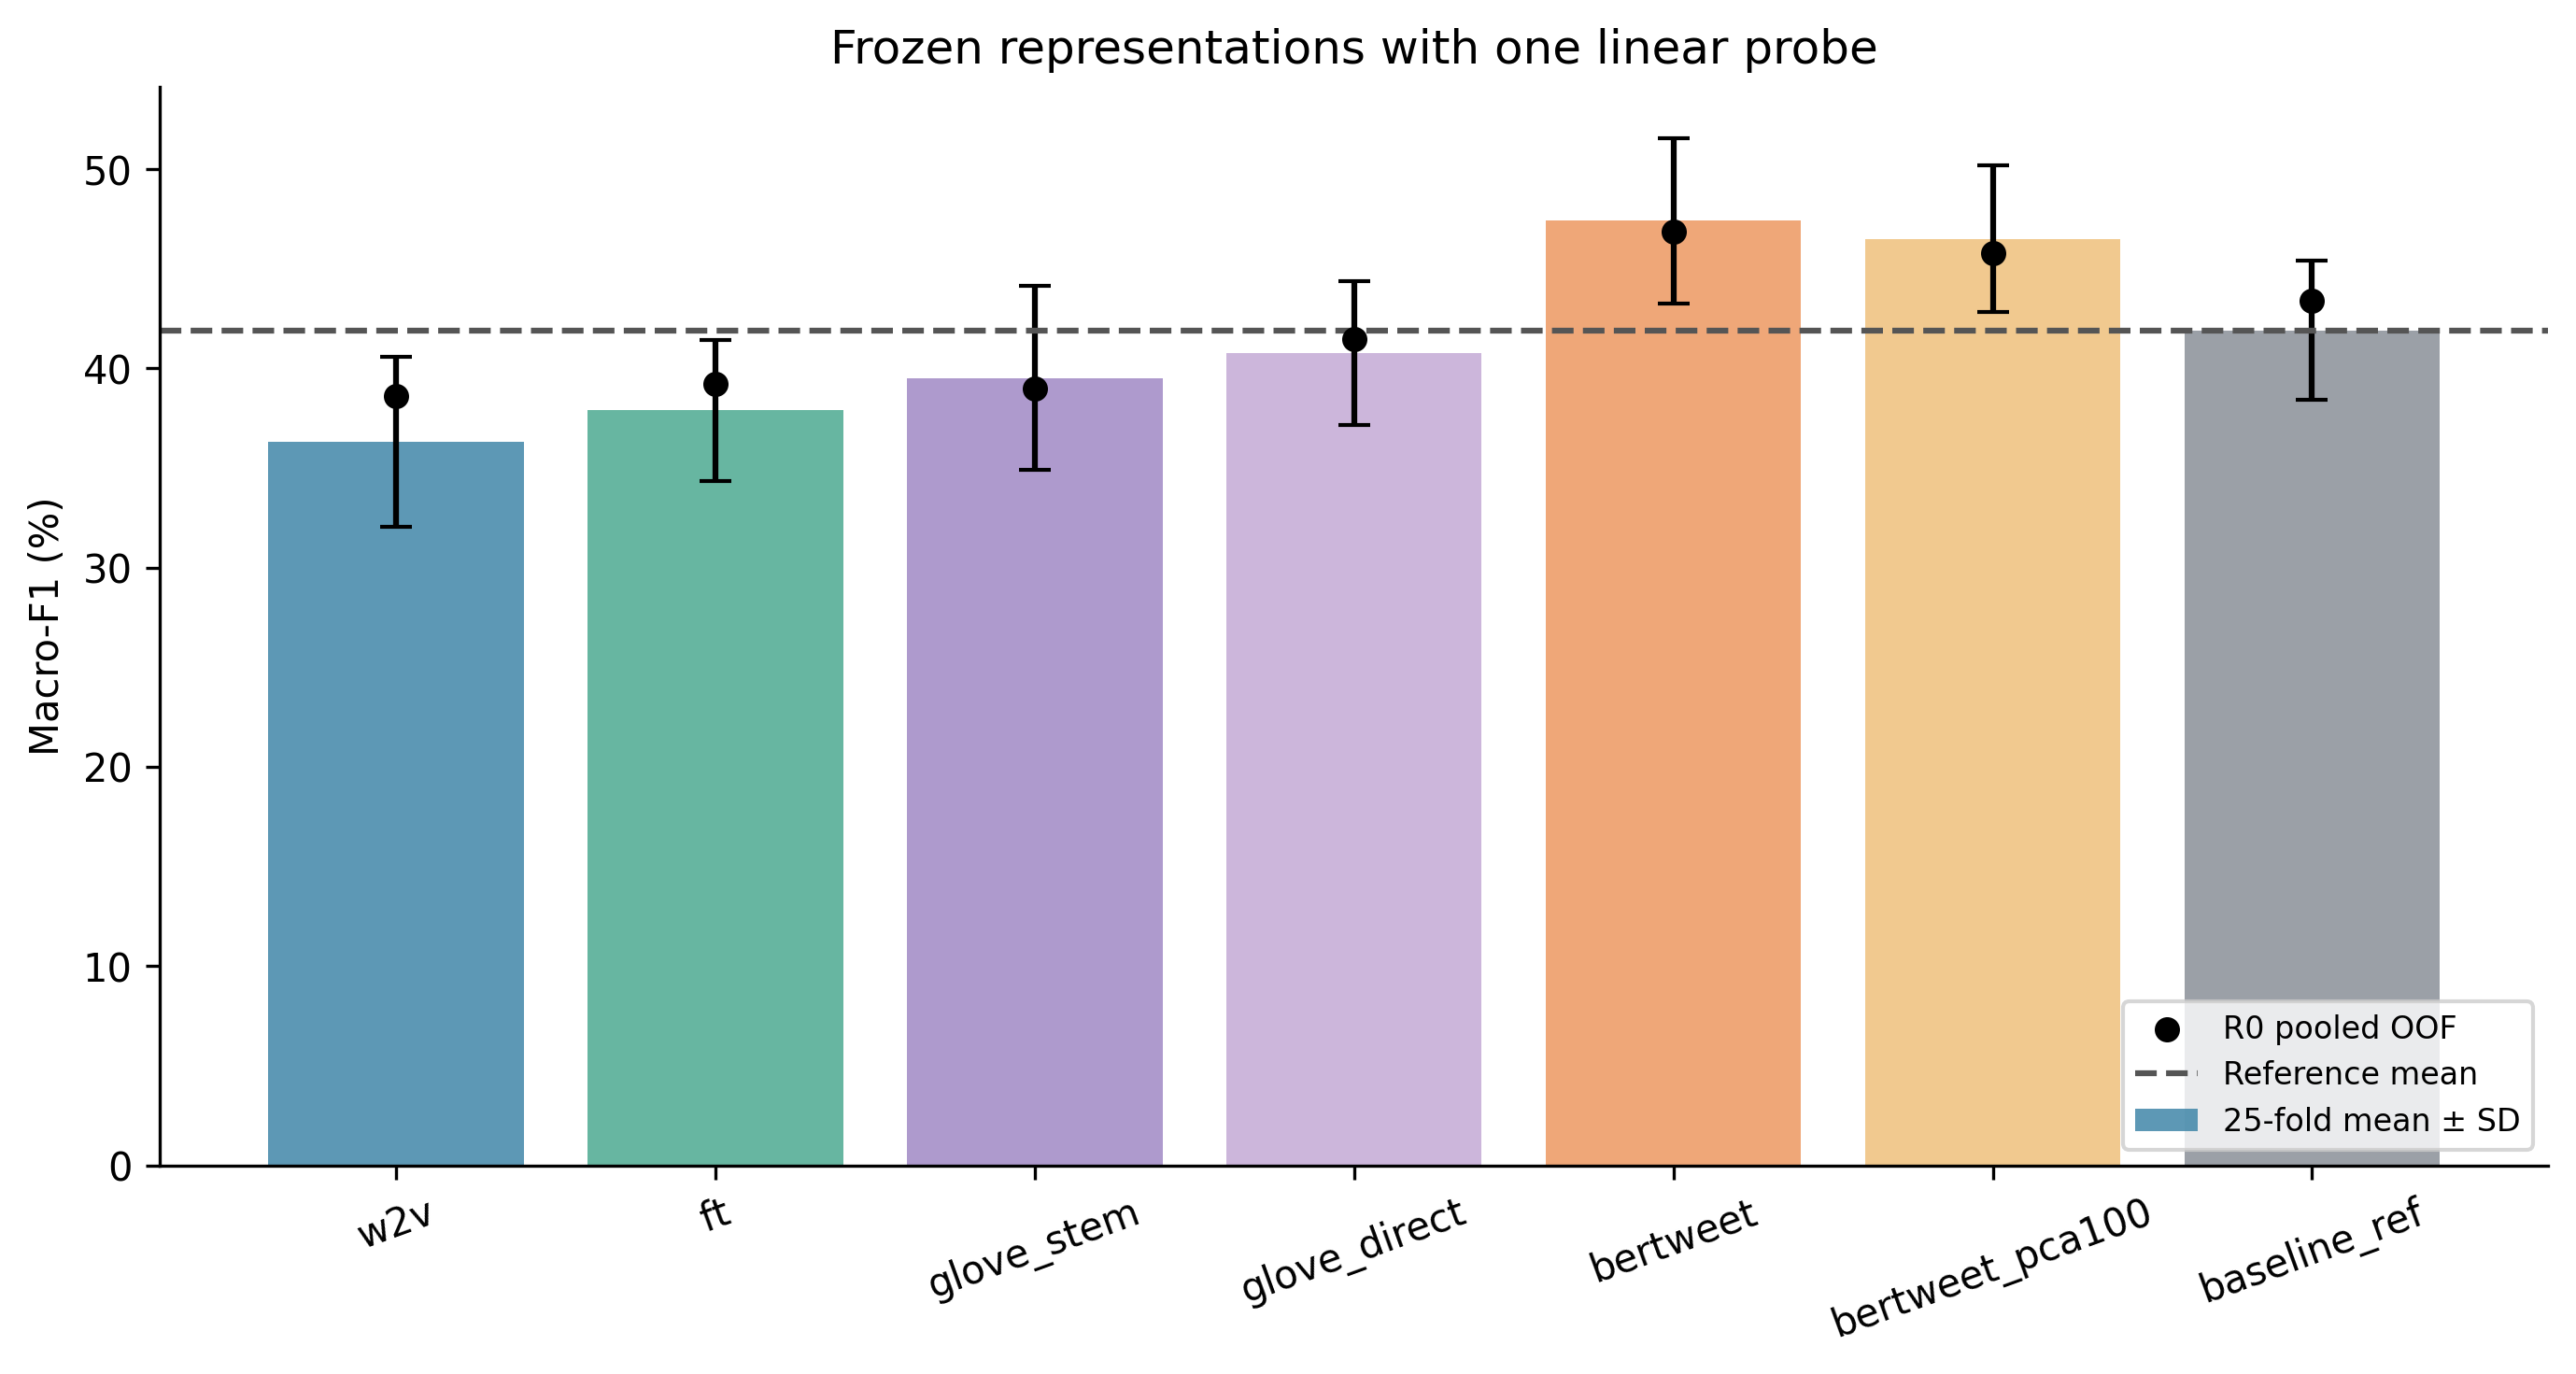

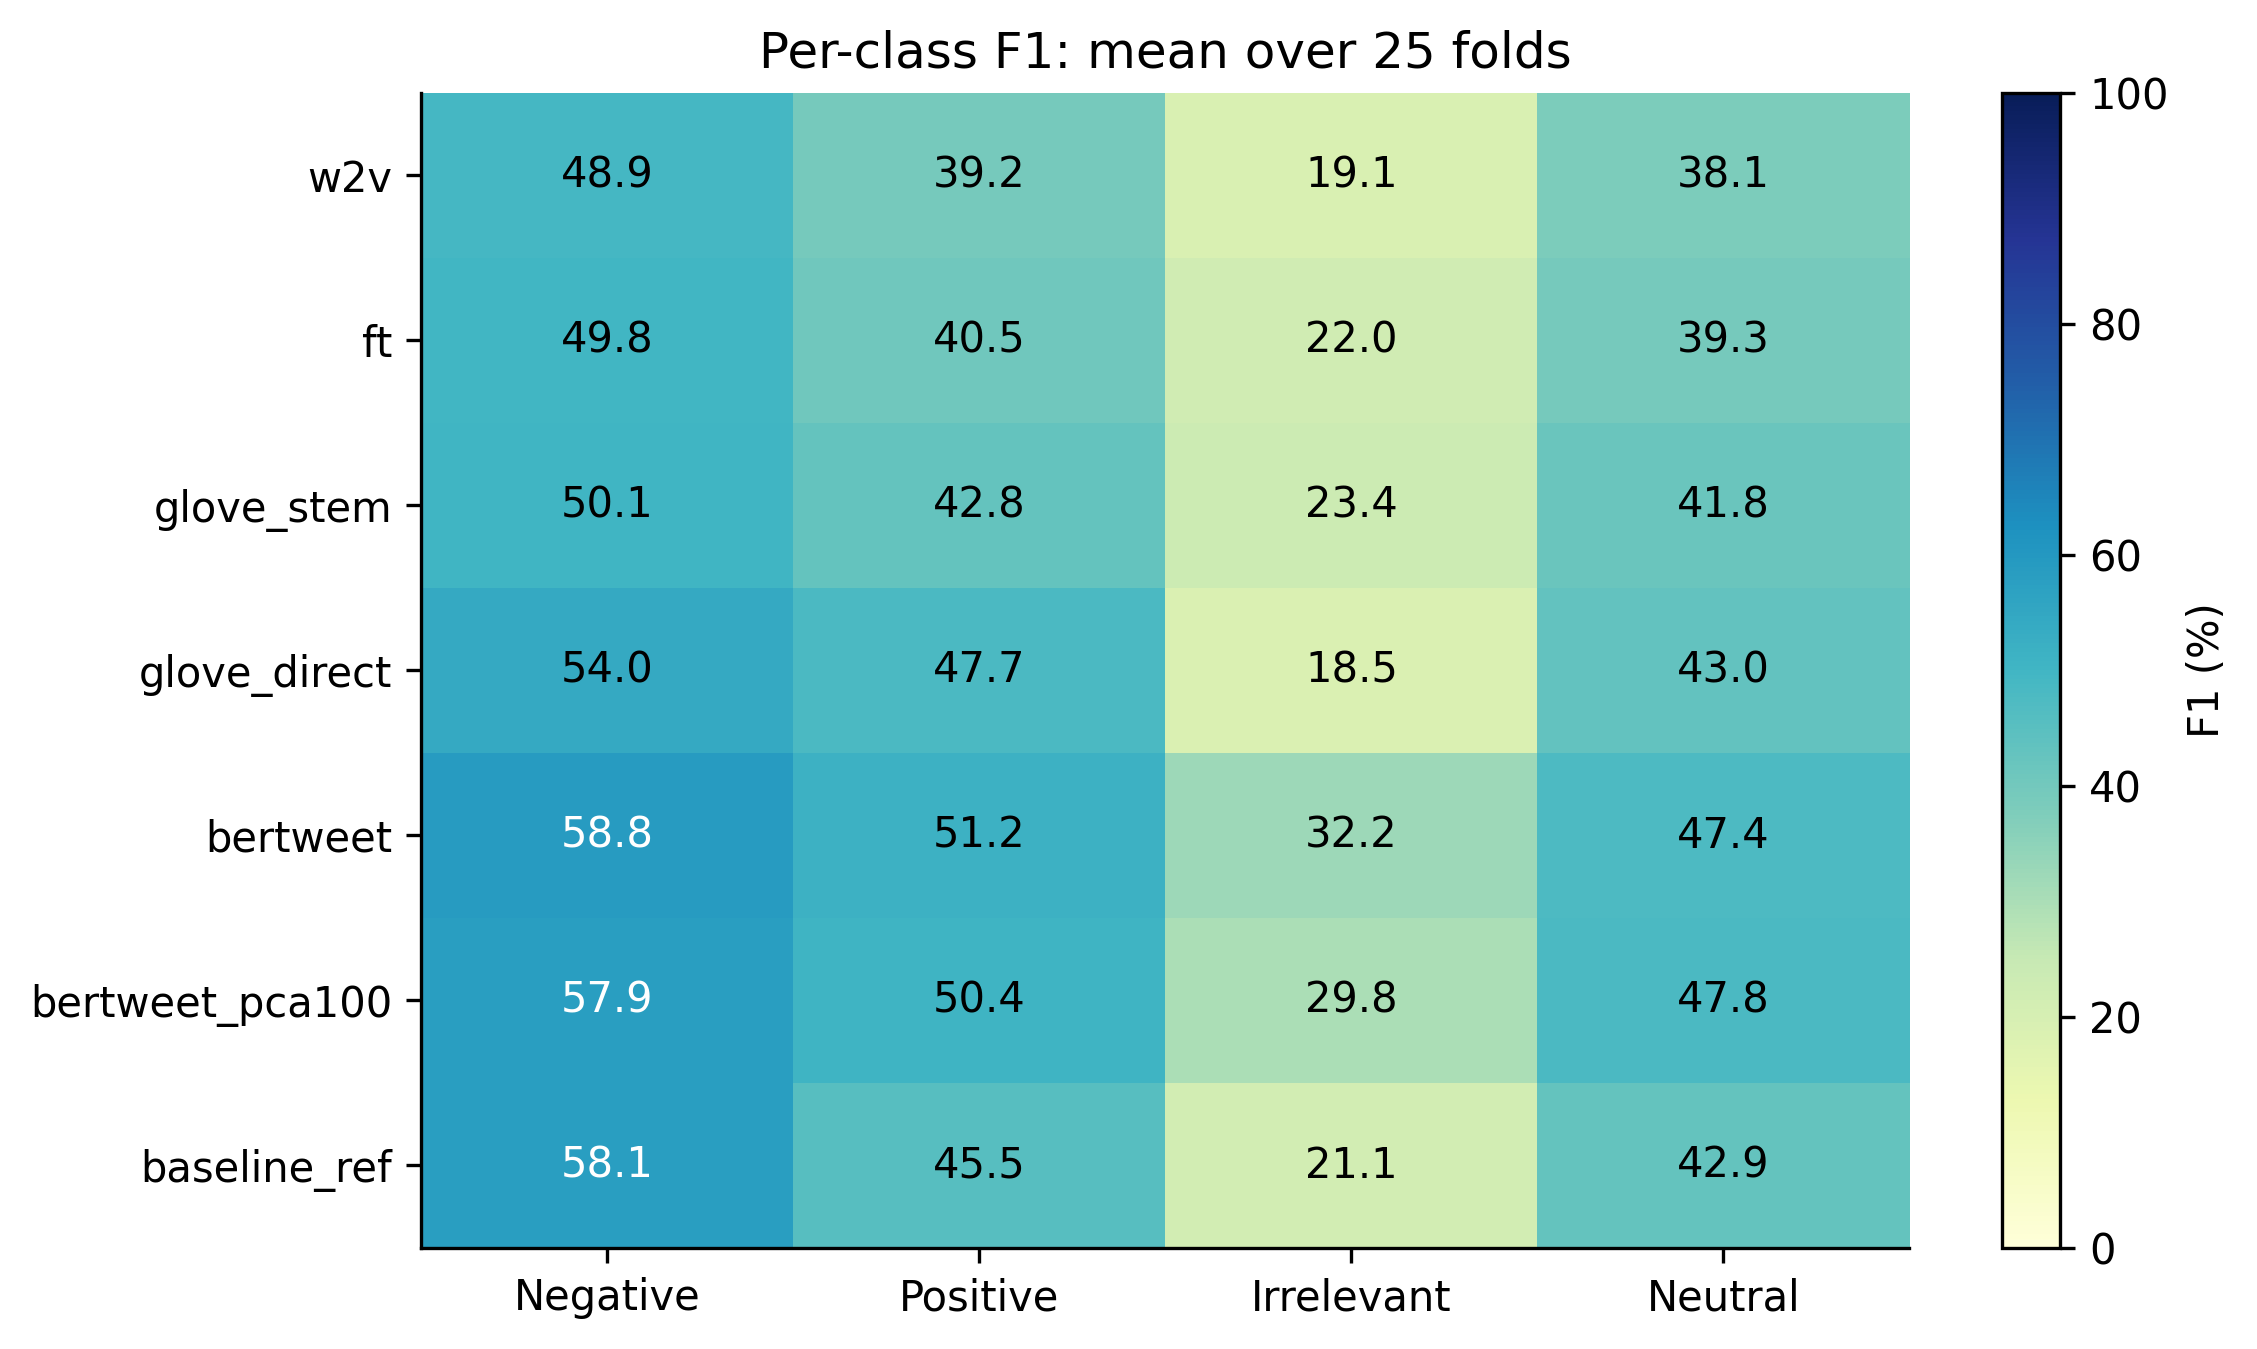

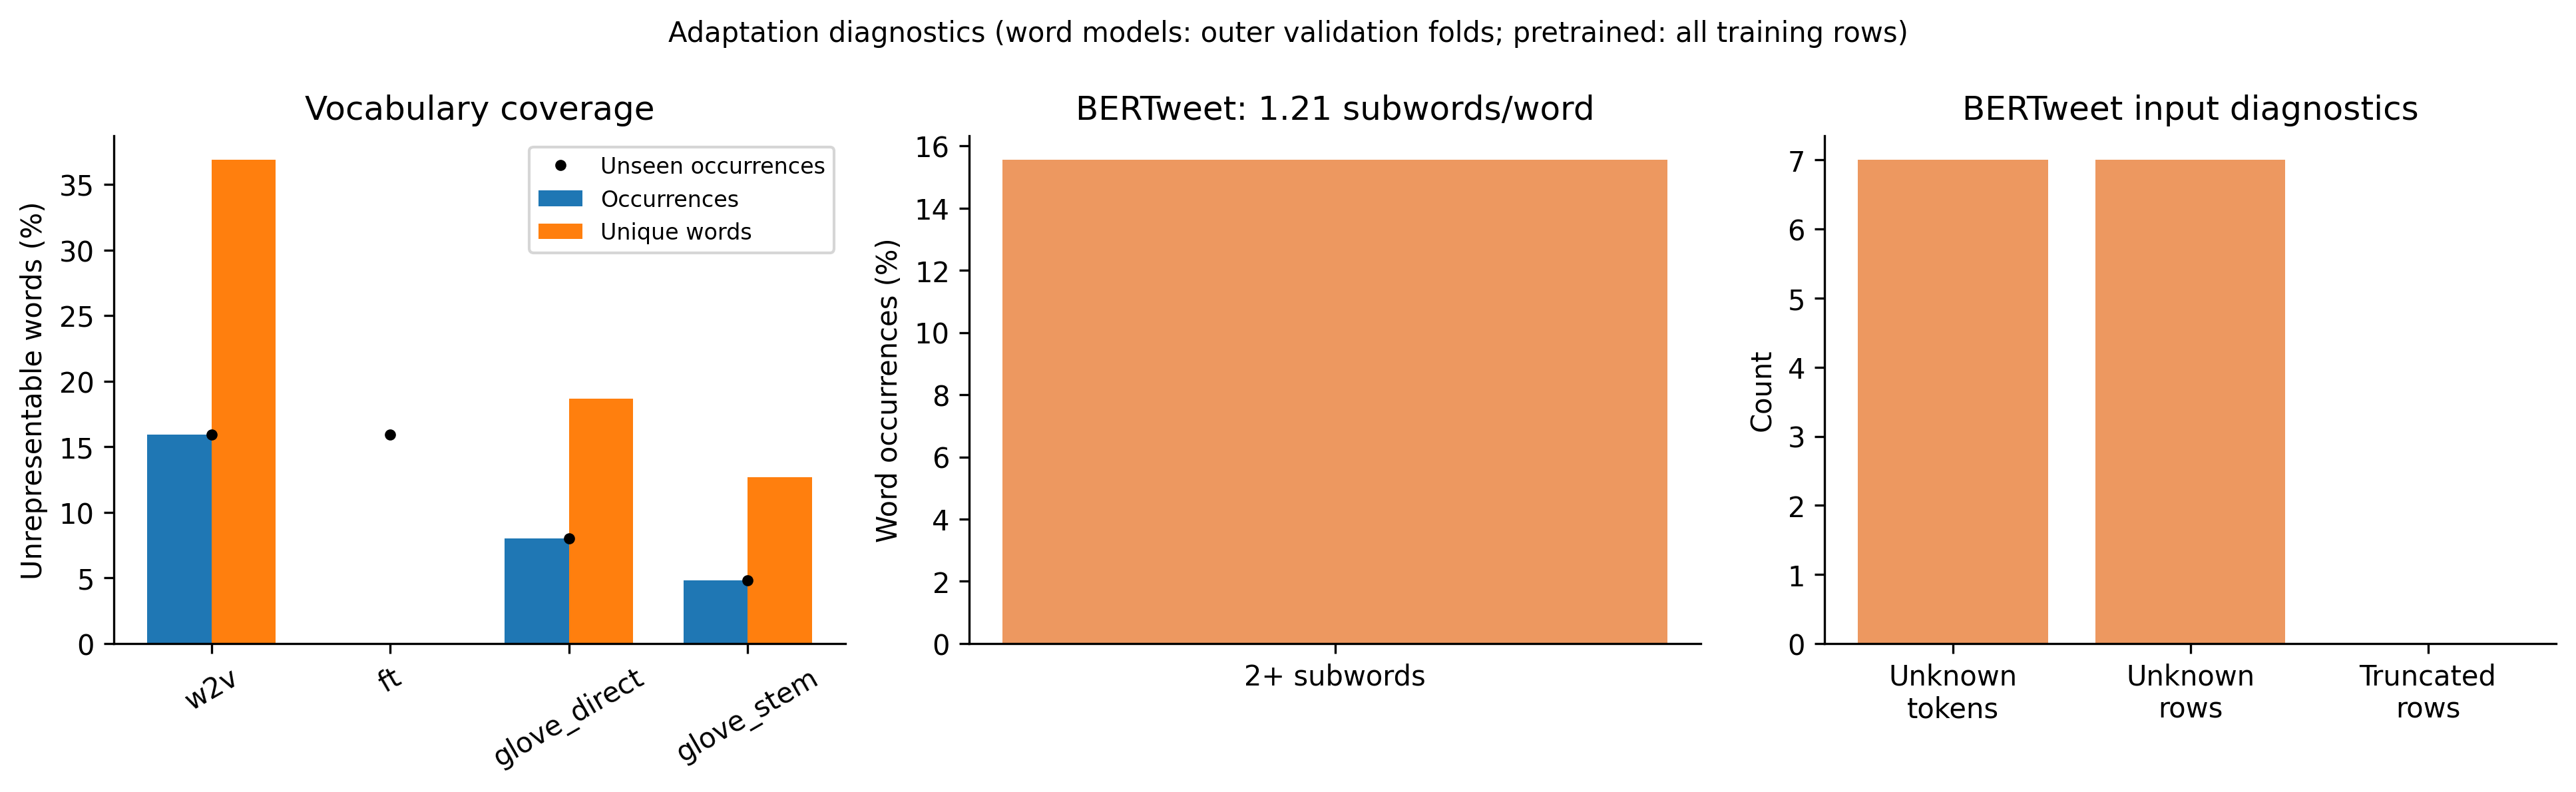

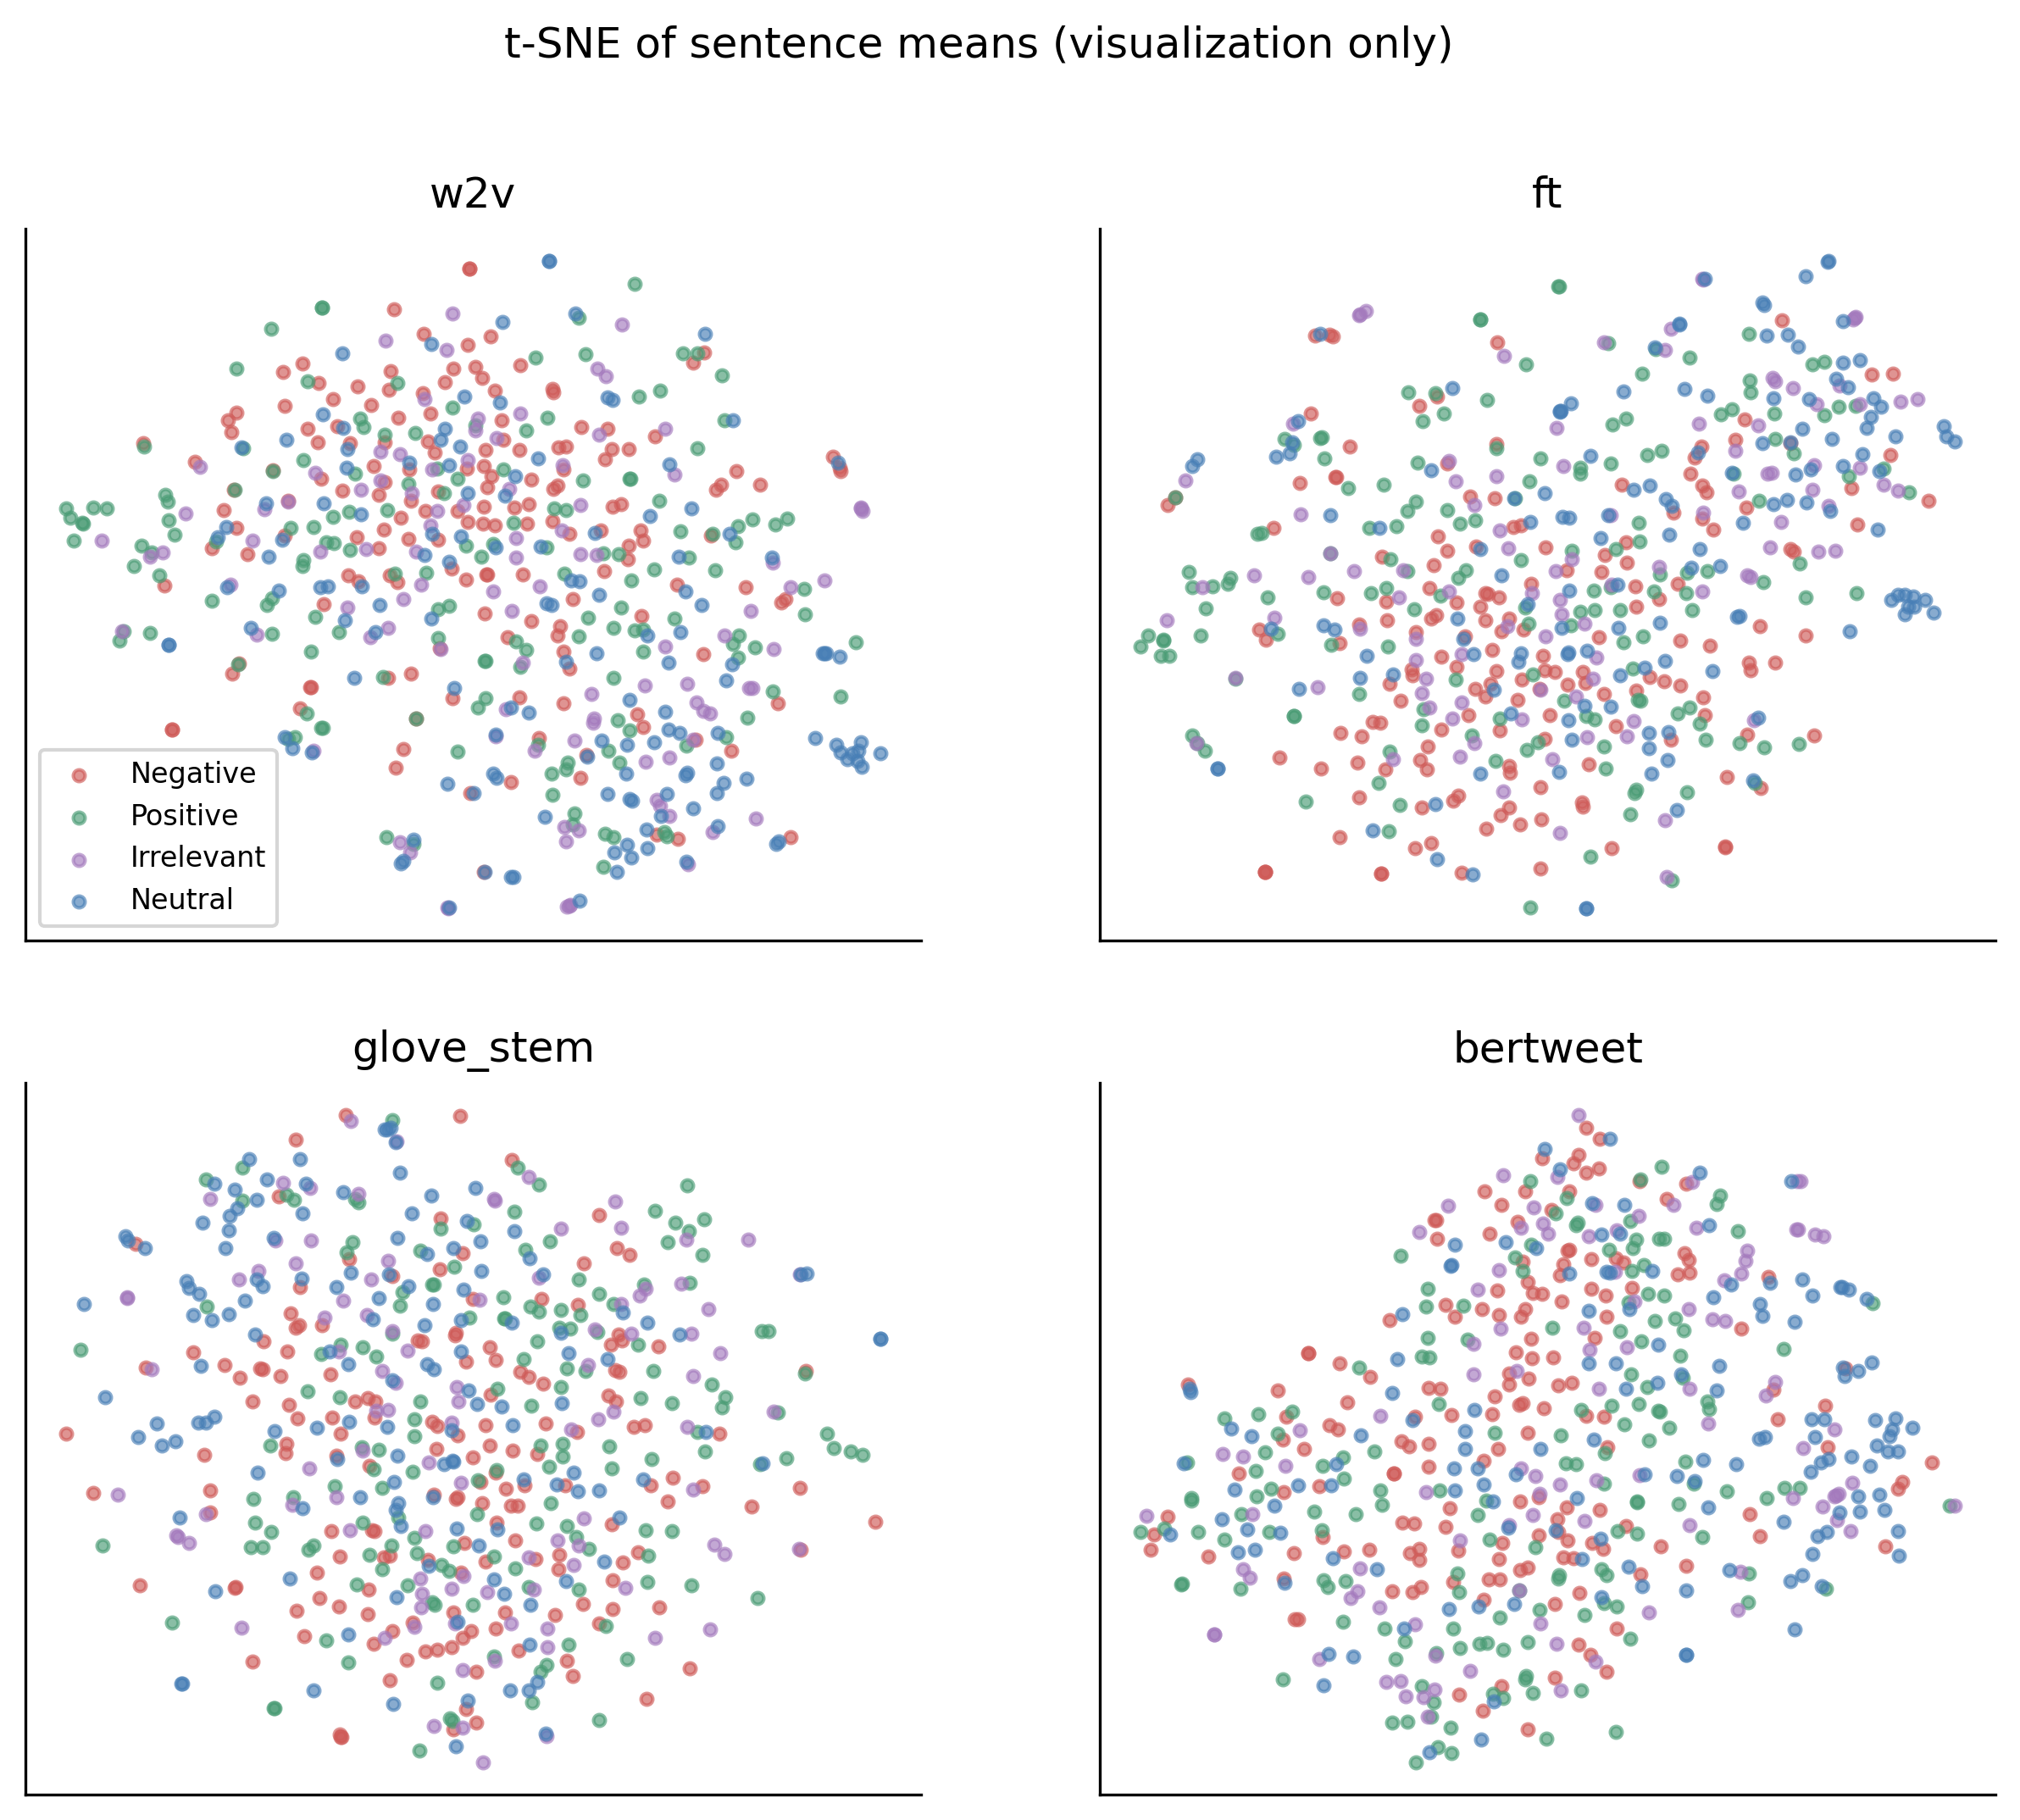

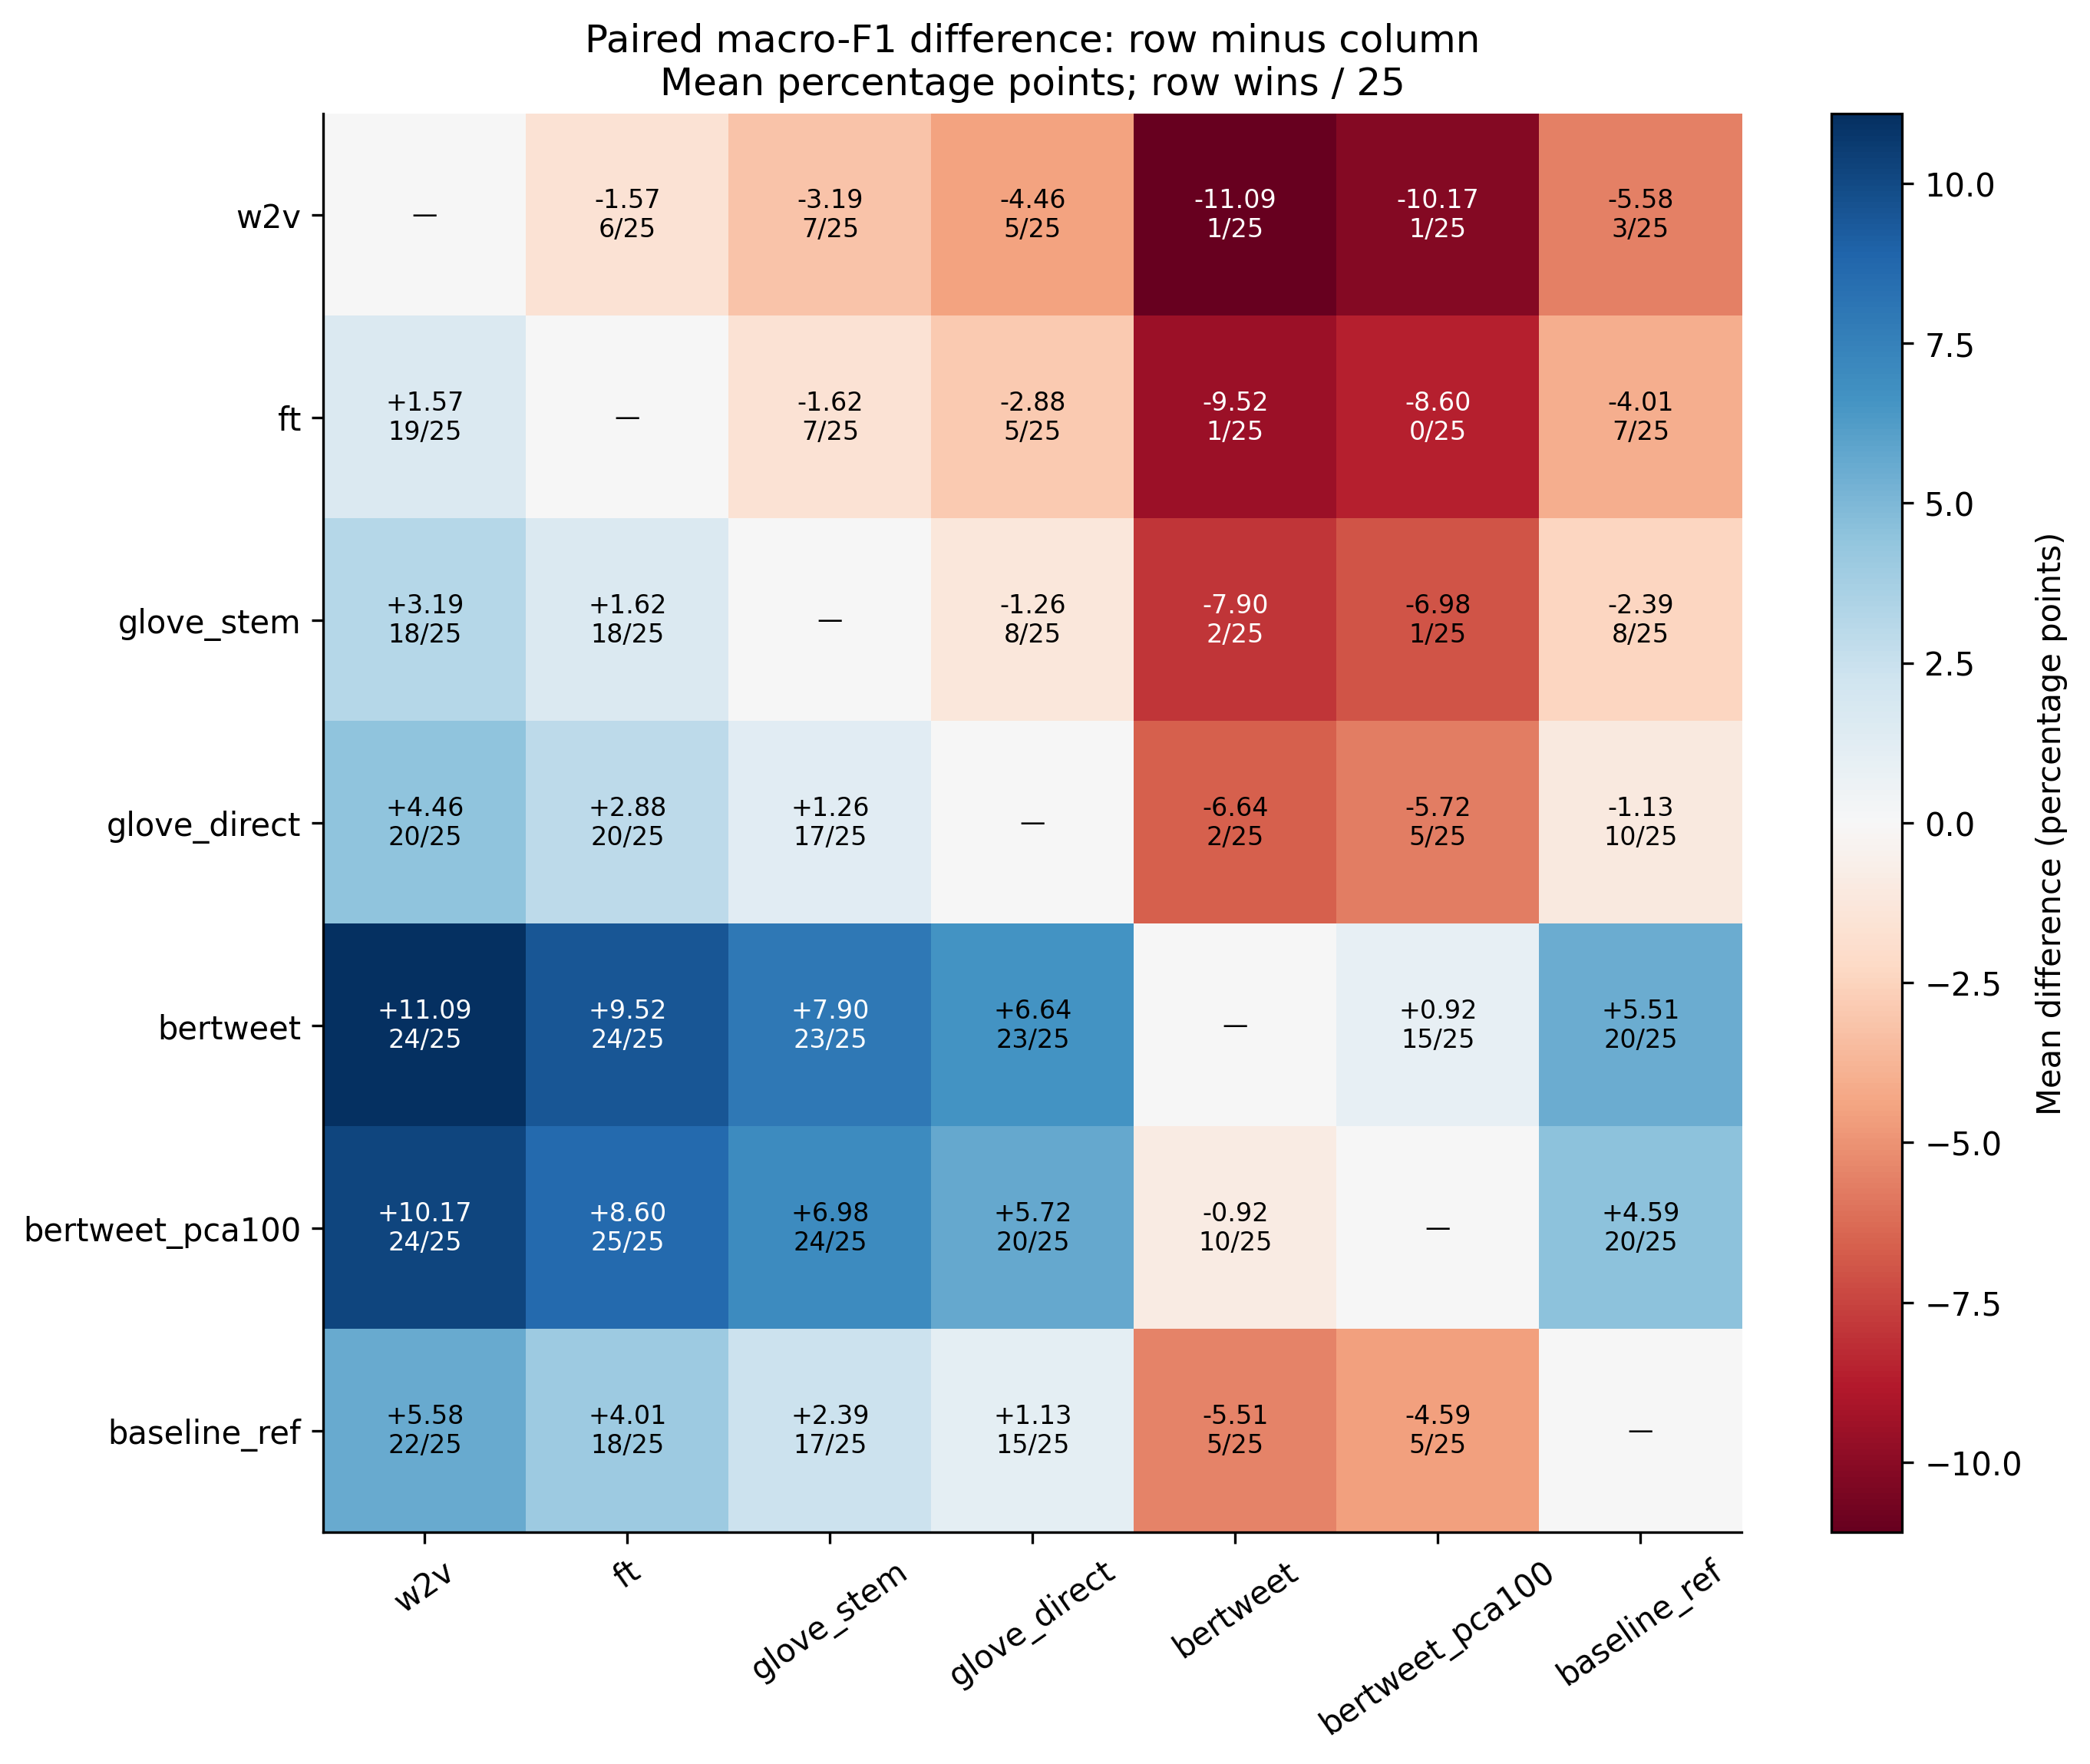

In [11]:
from IPython.display import Image, display
for name in ['F1_macro_f1', 'F2_class_f1', 'F3_coverage', 'F4_tsne', 'F5_pairwise_delta']:
    display(Image(filename=str(FIGURES / f'{name}.png')))